# Project 2 on Machine Learning: classification and regression, writing our own neural network code

**Data Analysis and Machine Learning FYS-STK3155/FYS4155, University of Oslo, fall 2026**

**Deadline: November 6 (midnight), 2026.** Published October 6, 2026.

This notebook is the Jupyter version of the project text (`Project2.pdf`). The
code cells are *starting points*, not solutions: they set up the Runge data of
project 1 and show how to fetch the MNIST data for part e). Everything else is
yours to write.


### Part a): Analytical warm-up

When using our gradient machinery from project 1, we will need the expressions for the cost/loss functions and their respective gradients. The functions whose gradients we need are:

1.  the mean-squared error (MSE) with and without the $L_1$ and $L_2$ norms (regression problems);

2.  the binary cross entropy (aka log loss) for binary classification problems with and without the $L_1$ and $L_2$ norms;

3.  the multiclass cross entropy cost/loss function (aka softmax cross entropy or just softmax loss function).

Set up these three cost/loss functions and their respective derivatives and explain the various terms. In this project you will however only use the MSE and the softmax cross entropy. The cross entropy and the softmax function are discussed in Sections 5.3 and 5.6 of the lecture notes, the cost functions for neural networks in Section [8.7](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-cost-function-and-the-optimisation-problem), and the regularization terms in Section [8.12](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#regularisation-and-hyperparameters).

We will test three activation functions for our neural network setup, these are

1.  the Sigmoid (aka *logit*) function,

2.  the RELU function and

3.  the Leaky RELU function.

Set up their expressions and their first derivatives. The activation functions are discussed in Section [8.6](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#activation-functions) of the lecture notes (the sigmoid in Section 8.6.1, the RELU family in Section 8.6.2), and in the lecture material of week 41 at <https://github.com/EducationalMaterialUiO/MachineLearningUiO/tree/main/doc/WeeklyMaterial/week41>.


In [2]:
# Part a): the cost functions, their gradients and the activation functions (with derivatives).
# The derivations belong in the theory section of the report.

import numpy as np
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that results agree with numpy to ~1e-15
import jax.numpy as jnp                    # only used for the gradient checks against jax.grad
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
import itertools
import os
from joblib import Parallel, delayed

np.random.seed(2026)   # so that your numbers can be compared with those of other students


# Activation functions and their derivatives (NumPy, so that training stays fast)
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def sigmoid_der(z):
    s = sigmoid(z)
    return s * (1 - s)

def ReLU(z):
    return np.where(z > 0, z, 0.0)

def ReLU_der(z):
    return np.where(z > 0, 1.0, 0.0)

def ReLU_leaky(z, alpha=0.01):
    return np.where(z > 0, z, alpha * z)

def ReLU_leaky_der(z, alpha=0.01):
    return np.where(z > 0, 1.0, alpha)

def identity(z):
    return z

def identity_der(z):
    return np.ones_like(z)

def softmax(z):
    e = np.exp(z - np.max(z, axis=1, keepdims=True))   # subtract the max: avoids overflow, same result
    return e / np.sum(e, axis=1, keepdims=True)


# Cost functions and their gradients with respect to the output of the network
def mse(predict, target):
    return np.mean((predict - target) ** 2)

def mse_der(predict, target):
    return 2.0 / len(target) * (predict - target)

def binary_cross_entropy(p, y):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def binary_cross_entropy_der(p, y):          # dC/dp; with a sigmoid output this becomes dC/dz = (p - y)/n
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return (p - y) / (p * (1 - p)) / len(y)

def cross_entropy(p, y_onehot):              # softmax cross entropy, p = softmax(z)
    return -np.mean(np.sum(y_onehot * np.log(np.clip(p, 1e-12, None)), axis=1))

def cross_entropy_der(p, y_onehot):          # dC/dz: the softmax Jacobian cancels
    return (p - y_onehot) / len(y_onehot)


# Gradients of the penalties lam*||W||_2^2 (L2) and lam*||W||_1 (L1), added to any of the costs above
def l2_der(W, lam):
    return 2.0 * lam * W

def l1_der(W, lam):
    return lam * np.sign(W)


def R_squared(y, y_prediction):
    return 1 - np.sum((y - y_prediction)**2) / np.sum((y - np.mean(y))**2)

In [3]:
import matplotlib.pyplot as plt
from cycler import cycler

# we use Paul tol's bright color scheme for the plots
Colors = (
    "#4477AA",
    "#EE6677",
    "#228833",
    "#CCBB44",
    "#66CCEE",
    "#AA3377",
    "#BBBBBB",
)


def plot_style():
    plt.style.use("seaborn-v0_8-darkgrid")

    plt.rcParams.update({
        "axes.prop_cycle": cycler(color=Colors),

        "font.family": "serif",
        "font.size": 14,
        "axes.labelsize": 16,
        "axes.titlesize": 18,
        "legend.fontsize": 12,
        "figure.figsize": (8, 6),
        "axes.grid": True,
        "grid.alpha": 0.9,
        "grid.linestyle": "solid",
        "text.usetex": True,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "xtick.major.size": 6,
        "xtick.minor.size": 3,
        "ytick.major.size": 6,
        "ytick.minor.size": 3,
        "xtick.major.width": 1.0,
        "xtick.minor.width": 0.75,
        "ytick.major.width": 1.0,
        "ytick.minor.width": 0.75,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "xtick.color": "black",
        "ytick.color": "black",
    })


plot_style()
legend_style = dict(frameon=True, facecolor="lightgray", edgecolor="gray", framealpha=0.7)
markers = ("o", "x", "^", "v", "d", "s")
os.makedirs("figures", exist_ok=True)


def save_fig(fig, name):
    fig.savefig(os.path.join("figures", name + ".pdf"), bbox_inches="tight")


def make_grid(values, key, rows, cols):
    """2D array with values[key + (rows[i], cols[j])] in row i and column j"""
    grid = np.zeros((len(rows), len(cols)))
    for (i, row), (j, col) in itertools.product(enumerate(rows), enumerate(cols)):
        grid[i, j] = values[key + (row, col)]
    return grid


def annotate(ax, grid, x, y, digits=4):
    """Writes the value of every cell of a heat map at the positions x (columns) and y (rows)"""
    v_max = np.max(grid)
    for (i, yi), (j, xj) in itertools.product(enumerate(y), enumerate(x)):
        if grid[i, j]/v_max >= 0.55:
            ax.text(xj, yi, f"{grid[i, j]:.{digits}f}", ha="center", va="center", color="k", fontsize=9)
        else:
            ax.text(xj, yi, f"{grid[i, j]:.{digits}f}", ha="center", va="center", color="w", fontsize=9)


penalty_name = {None: "none", "ridge": "L2", "lasso": "L1"}

### Reminder about the gradient machinery from project 1

In the setup of a neural network code you will need your gradient descent codes from project 1. For neural networks we will recommend using stochastic gradient descent (Section 4.7 of the lecture notes) with either the RMSprop or the Adam algorithms for updating the learning rates (Sections 4.10 and 4.11). But you should feel free to try plain gradient descent as well. As in project 1 and in the lecture notes we call the learning rate $\gamma$ (many texts call it $\eta$).

We recommend reading chapter 8 on optimization from the textbook of Goodfellow, Bengio and Courville at <https://www.deeplearningbook.org/>. This chapter contains many useful insights and discussions on the optimization part of machine learning. A useful reference on the back propagation algorithm is Nielsen’s book at <http://neuralnetworksanddeeplearning.com/>.

You will find the Python [Seaborn package](https://seaborn.pydata.org/generated/seaborn.heatmap.html) useful when plotting the results as function of the learning rate $\gamma$ and the hyperparameter $\lambda$.


### Part b): Writing your own neural network code

Your aim now, and this is the central part of this project, is to write your own FFNN code implementing the back propagation algorithm discussed in the lecture material of week 41 (see <https://github.com/EducationalMaterialUiO/MachineLearningUiO/tree/main/doc/WeeklyMaterial/week41>) and week 42 (see <https://github.com/EducationalMaterialUiO/MachineLearningUiO/tree/main/doc/WeeklyMaterial/week42>), and in Section [8.8](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#backpropagation) of the lecture notes. The notation and the feed-forward pass are set up in Section [8.5](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#notation-and-the-feed-forward-pass), the general dense-layer case and the four equations of backpropagation in Sections [8.8.3](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-general-case-dense-layers) and [8.8.4](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-four-equations-of-backpropagation), and the full algorithm in Section [8.8.5](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-algorithm). A complete network from scratch, including a check of the gradient against automatic differentiation, is discussed in Section [8.13](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#a-neural-network-from-scratch). The exercises of week 41 (`exercisesweek41.ipynb`) give you a template for the code: samples are stored in the rows of the input, the weight matrix of a layer has shape (inputs, outputs), and the feed-forward step of a layer reads `a @ W + b`.

We will focus on a regression problem first, using the one-dimensional Runge function

$$
f(x) = \frac{1}{1+25x^2},
$$

from project 1.

Use only the mean-squared error as cost function (no regularization terms) and write an FFNN code for a regression problem with a flexible number of hidden layers and nodes using only the Sigmoid function as activation function for the hidden layers. Initialize the weights using a normal distribution (see Section [8.10](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#weight-initialisation) for how the width of that distribution should depend on the number of inputs of a layer). How would you initialize the biases? And which activation function would you select for the final output layer? And how would you set up your design/feature matrix? Hint: does it have to represent a polynomial approximation as you did in project 1?

Train your network and compare the results with those from your OLS regression code from project 1 using the one-dimensional Runge function. When comparing your neural network code with the OLS results from project 1, use the same data sets which gave you the best MSE score. Moreover, use the polynomial order from project 1 that gave you the best result. Compare these results with your neural network with one and two hidden layers using $50$ and $100$ hidden nodes, respectively.

Comment your results and give a critical discussion of the results obtained with the OLS code from project 1 and your own neural network code. Make an analysis of the learning rates employed to find the optimal MSE score. Test both stochastic gradient descent with RMSprop and Adam and plain gradient descent with different learning rates.

You should, as you did in project 1, scale your data (Section 3.13 of the lecture notes).


In [4]:
# LLM-assisted (Kimi K2.6, level 1): moved from FYSSTK4155p2.py into the notebook when merging
# Parts b) and c), regression of the Runge function: FFNN class and helper functions (from FYSSTK4155p2.py)
# plot_style() is defined above, and the FFNN class has its own optimisers (apply_gradients)
import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import median_filter
from scipy.special import expit

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from tqdm import trange

# Defining the relevant functions of the neural network

def runge(x):
    return 1/(1+25*np.asarray(x)**2)

def MSE(y_true, y_pred):
    if y_true.shape != y_pred.shape:
        raise ValueError("y_true and y_pred have different shapes.")
    return np.mean((y_true - y_pred)**2)

def activation(z, type):
    if type == "sigmoid":
        return expit(z)
    elif type == "ReLU":
        return np.maximum(0, z)
    elif type == "LReLU":
        return np.where(z > 0, z, 0.01 * z)     # here we have hardcoded alpha = 0.01
    elif type == "linear":
        return z
    else:
        raise ValueError("Im not familiar with your activation function of choice! Please choose between 'sigmoid', 'ReLU', 'LReLU' and 'linear'.")

def activation_derivative(z, type):
    if type == "sigmoid":
        s = expit(z)
        return s * (1 - s)
    elif type == "ReLU":
        return (z > 0).astype(float)
    elif type == "LReLU":
        return np.where(z > 0, 1.0, 0.01)     # here we have hardcoded alpha = 0.01
    elif type == "linear":
        return np.ones_like(z)
    else:
        raise ValueError("Im not familiar with your activation function of choice! PLease choose between 'sigmoid', 'ReLU', 'LReLU' and 'linear'.")


class FFNN:
    """


    LLM-assisted
    ------------
    Tool: Moonshot Kimi K2.6 (November 2026)
    Role: Generate skeleton code for a FFNN *class*.
    Modifications: Reworked logic and adapted to project 2 (including parts from project 1). Added comments for clarity.
    """
    def __init__(self, layers, hidden_activation="sigmoid", seed=2026):

        self.layer_sizes        = list(layers)
        self.hidden_activation  = hidden_activation

        rng                     = np.random.default_rng(seed)

        self.weights            = []
        self.biases             = []

        for fan_in, fan_out in zip(layers[:-1], layers[1:]):
            # Xavier-type normal initialization, good for sigmoid
            std = np.sqrt(2.0 / (fan_in + fan_out))
            self.weights.append(rng.normal(0.0, std, size=(fan_in, fan_out)))
            self.biases.append(np.zeros((1, fan_out)))


        self.r_w                = [np.zeros_like(W) for W in self.weights]
        self.r_b                = [np.zeros_like(b) for b in self.biases]

        self.opt_w              = [{} for _ in self.weights]     # LLM-assisted
        self.opt_b              = [{} for _ in self.biases]      # LLM-assisted
        self.opt_t              = 0

        self.m_w                = [np.zeros_like(W) for W in self.weights]
        self.v_w                = [np.zeros_like(W) for W in self.weights]

        self.m_b                = [np.zeros_like(b) for b in self.biases]
        self.v_b                = [np.zeros_like(b) for b in self.biases]

        self.t                  = 0


    def forward(self, X):
        # Returns the activations and pre-activations for each layer given input X
        A = [np.asarray(X, dtype=float)]
        Z = []
        for layer, (W, b) in enumerate(zip(self.weights, self.biases)):
            z = A[-1] @ W + b
            kind = "linear" if layer == len(self.weights) - 1 else self.hidden_activation
            Z.append(z)
            A.append(activation(z, kind))
        return A, Z

    def predict(self, X):
        # Returns the output of the network for input X
        return self.forward(X)[0][-1]

    def backward(self,A,Z,Y):
        """
        Gradients of C = (1/(2m)) sum_i (y_pred_i - y_true_i)^2

        Delta is NOT divided by m so gradients are averaged once below.
        Add L1/L2 gradients here for part d.?
        """
        m = Y.shape[0]
        grad_w = [None] * len(self.weights)
        grad_b = [None] * len(self.biases)
        delta = A[-1] - Y  # linear output + half-MSE
        for l in reversed(range(len(self.weights))):
            grad_w[l] = A[l].T @ delta / m
            grad_b[l] = np.sum(delta, axis=0, keepdims=True) / m
            if l > 0:
                delta = (delta @ self.weights[l].T) * activation_derivative(Z[l - 1], self.hidden_activation)
        return grad_w, grad_b

    def apply_gradients(self, grad_w, grad_b,gamma, optimizer):

        self.opt_t += 1



        # Update weights and biases using the computed gradients
        if optimizer == "gd":

            for l in range(len(self.weights)):
                self.weights[l] -= gamma * grad_w[l]
                self.biases[l]  -= gamma * grad_b[l]

        elif optimizer == "RMSprop":

            rho = 0.99      # hardcoded, projecrt 1 vals
            eps = 1e-9      # hardcoded, projecrt 1 vals


            for l in range(len(self.weights)):

                self.r_w[l] = rho * self.r_w[l] + (1-rho) * grad_w[l]**2
                self.r_b[l] = rho * self.r_b[l] + (1-rho) * grad_b[l]**2

                self.weights[l] -= gamma * grad_w[l] / (
                    np.sqrt(self.r_w[l]) + eps
                )

                self.biases[l] -= gamma * grad_b[l] / (
                    np.sqrt(self.r_b[l]) + eps
                )

        elif optimizer == "Adam":
            # hardcoded, project 1 vals

            eps     = 1e-9
            beta1   = 0.9
            beta2   = 0.999

            self.t += 1

            for l in range(len(self.weights)):

                #1st moment
                self.m_w[l] = beta1*self.m_w[l] + (1-beta1)*grad_w[l]
                self.m_b[l] = beta1*self.m_b[l] + (1-beta1)*grad_b[l]

                #2nd
                self.v_w[l] = beta2*self.v_w[l] + (1-beta2)*(grad_w[l]**2)
                self.v_b[l] = beta2*self.v_b[l] + (1-beta2)*(grad_b[l]**2)

                # bias correction
                m_w_hat = self.m_w[l] / (1-beta1**self.t)
                m_b_hat = self.m_b[l] / (1-beta1**self.t)

                v_w_hat = self.v_w[l] / (1-beta2**self.t)
                v_b_hat = self.v_b[l] / (1-beta2**self.t)

                # finally update the params
                self.weights[l] -= gamma*m_w_hat/(np.sqrt(v_w_hat)+eps)
                self.biases[l]  -= gamma*m_b_hat/(np.sqrt(v_b_hat)+eps)

        else:
            raise ValueError("Check arguments of apply_gradients, specifically the chosen optimizer. Choose betwwen 'gd', 'RMSprop' or 'Adam'.")


    def fit(self, X_train, y_train, X_val, y_val, epochs=1500,gamma=0.1, batch_size=None, optimizer="gd", seed=2026):
        """
        Train the neural network using mini-batch gradient descent.

        batch_size = None means full-batch gradient descent.
        batch_size = 1 means stochastic gradient descent.

        """
        rng         = np.random.default_rng(seed)
        n           = len(X_train)
        batch_size  = n if batch_size is None else batch_size
        history     = {"train_mse": [], "val_mse": []}

        progress    = trange(epochs,desc="FFNN training", unit="epoch")
        for epoch in progress:
            order = rng.permutation(n)
            for start in range(0, n, batch_size):
                ix              = order[start:start + batch_size]
                A, Z            = self.forward(X_train[ix])
                grad_w, grad_b  = self.backward(A, Z, y_train[ix])
                self.apply_gradients(grad_w, grad_b, gamma, optimizer)

            history["train_mse"].append(MSE(y_train, self.predict(X_train)))
            history["val_mse"].append(MSE(y_val, self.predict(X_val)))

        return history

def comparing_Optimizer(architectures, X_train, y_train, X_val, y_val,gammas, epochs,mse_type):

    results     = {}
    optimizers  = {
                    "Plain GD"      : ("gd", None),
                    "Plain SGD"     : ("gd", 1),
                    "SGD + RMSprop" : ("RMSprop", 16),
                    "SGD + Adam"    : ("Adam", 16)}


    for architect, layers in architectures.items():

        results[architect] = {}

        for label, (optimizer, batch_size) in optimizers.items():

            mse_values = []

            for gamma in gammas:

                network = FFNN(layers,hidden_activation="sigmoid",seed=2026)

                hist = network.fit(X_train, y_train,X_val, y_val,epochs=epochs,gamma=gamma,batch_size=batch_size,optimizer=optimizer,seed=2026)

                if mse_type in ("min","minimum"):

                    mse_best  = np.min(hist["val_mse"])
                    mse_values.append(mse_best)

                elif mse_type in ("final","last"):

                    mse_final = hist["val_mse"][-1]
                    mse_values.append(mse_final)

                else:
                    ValueError("Hey! Please choose a type of MSE: 'min','minimum' or 'final','last'.")

            results[architect][label] = np.array(mse_values)

    return results

def finite_difference_check(net,X,Y,epsilon=1e-6):
    """
    Check the gradients computed by backpropagation using finite differences before training the network.
    This is a sanity check to ensure that the gradients are computed correctly.
    """
    A, Z = net.forward(X)
    dw, db = net.backward(A, Z, Y)
    checks = [(net.weights[0], dw[0], (0, 0)),
            (net.biases[0], db[0], (0, 0))]

    for param, grad, index in checks:
        old             = param[index]
        param[index]    = old + epsilon
        plus            = 0.5 * MSE(Y, net.predict(X))
        param[index]    = old - epsilon
        minus           = 0.5 * MSE(Y, net.predict(X))
        param[index]    = old
        numerical       = (plus - minus) / (2 * epsilon)
        analytical      = grad[index]
        print(f"gradient check: numeric={numerical:.8g} analytical={analytical:.8g}"
            f" absolute error={abs(numerical - analytical):.2e}")
        assert np.isclose(numerical, analytical, rtol=2e-4, atol=1e-7)

def hessian_lambda_max(net, X, Y, iterations=200, eps=1e-5, seed=2026):
    """
    Plain gradient descent is only stable for gamma < 2 / lambda_max.

    LLM-assisted
    ------------
    Tool: Kimi K2.6 (Moonshotai, Nov 2026)
    Role: Conributed with code debugging and the for loop for the power iteration.
    """
    params = net.weights + net.biases
    theta0 = [P.copy() for P in params]

    def gradient():
        A, Z = net.forward(X)
        grad_w, grad_b = net.backward(A, Z, Y)
        return np.concatenate([g.ravel() for g in grad_w + grad_b])

    def shift(v, step):
        k = 0
        for P, P0 in zip(params, theta0):
            P[...] = P0 + step * v[k:k + P0.size].reshape(P0.shape)
            k += P0.size

    rng = np.random.default_rng(seed)
    v = rng.normal(size=sum(P.size for P in theta0))
    v /= np.linalg.norm(v)
    lam = 0.0
    for _ in range(iterations):
        shift(v, eps);  g_plus = gradient()
        shift(v, -eps); g_minus = gradient()
        Hv = (g_plus - g_minus) / (2 * eps)
        lam = v @ Hv
        v = Hv / np.linalg.norm(Hv)
    shift(v, 0.0)                       # restore the parameters
    return lam

"""
Functions for generating project 1 data:

- Runge function with normal distributed noise
- polynomila features
- prediction from OLS fit

"""

def project1_runge_data(seed,n,test_size):

    rng = np.random.default_rng(seed=seed)
    x   = np.linspace(-1,1,n)
    y   = runge(x) + rng.normal(0,0.1,size=len(x))
    return train_test_split(x,y, test_size=test_size, random_state=seed)


def polynomial_features(x,degree):

    return np.column_stack([np.asarray(x)**j for j in range(1, degree+1)])


def OLS_pred(x_train, y_train, x_eval, degree):

    X_train_pol = polynomial_features(x_train, degree)
    X_eval_pol  = polynomial_features(x_eval, degree)

    X_mean = np.mean(X_train_pol, axis=0)
    y_mean = np.mean(y_train)
    coefficients = np.linalg.pinv(X_train_pol - X_mean) @ (y_train-y_mean)

    return (X_eval_pol - X_mean) @ coefficients + y_mean


"""
Lets plot
LLM-assisted
    ------------
    Tool: Moonshot Kimi K2.6(Nov 2026)
    Role: reworked my plotting skeleton code.
    Modifications: Tweaks to fit our visualization of the data.
"""

def plot_learning_curves(history, ols_train, ols_val):


    fig, ax = plt.subplots()

    color_list = [Colors[0], Colors[1]]     # Paul Tol bright
    for i, (label, hist) in enumerate(history.items()):
        color = color_list[i]

        epochs = np.arange(1, len(hist["train_mse"]) + 1)

        ax.plot(
            epochs,
            hist["train_mse"],
            linestyle="--",
            label=f"{label} (train)",
            color=color
        )

        ax.plot(
            epochs,
            hist["val_mse"],
            label=f"{label} (validation)",
            color=color
        )
    ax.axhline(0.1**2, color="k", linestyle=":", label=r"$\sigma^2=0.01$")
    ax.axhline(ols_train, color="k", linestyle="--", label=r"OLS, degree 11 (train)")
    ax.axhline(ols_val, color="k", linestyle="-.", label=r"OLS, degree 11 (validation)")

    ax.set_xlabel("epoch")
    ax.set_ylabel("MSE")
    ax.set_yscale("log")
    ax.set_xscale("log")
    ax.legend()
    save_fig(fig, "learning_curves")

    plt.show()

def plot_comparing_Optimizers(results,gammas,ols_mse,gd_limits=None):

    colors = {
        "Plain GD": Colors[0],          # Paul Tol bright
        "Plain SGD": Colors[1],
        "SGD + RMSprop": Colors[3],
        "SGD + Adam": Colors[2]
    }

    n_arch = len(results)

    fig, axes = plt.subplots(1, n_arch,figsize=(7*n_arch-1, 5),sharey=True,squeeze=False)

    for ax, (architecture, curves) in zip(axes.flat, results.items()):

        for label, mse_values in curves.items():

            ax.plot(gammas,mse_values,marker="o",markersize=5,linewidth=1.8,color=colors[label],label=label)

        ax.axhline(ols_mse,color="k",linestyle="--",label="OLS, degree 11")

        # Expected noise variance
        ax.axhline(0.1**2,color="k",linestyle=":",label=r"$\sigma^2=0.01$")

        # stability limit of plain GD, gamma = 2 / lambda_max of the Hessian (LLM-assisted, Kimi K2.6)
        if gd_limits is not None:
            ax.axvline(gd_limits[architecture],color=Colors[0],linestyle="-.",label=r"$2/\lambda_\mathrm{max}$ (GD limit)")

        ax.set_xscale("log")
        ax.set_yscale("log")

        ax.set_title(architecture)
        ax.set_xlabel(r"learning rate $\gamma$")
    axes[0, 0].legend(loc="lower left", bbox_to_anchor=(0.0, 0.05))

    axes[0, 0].set_ylabel("validation MSE")
    save_fig(fig, "comparing_optimizes")
    plt.show()

def plot_comparing_Activations(histories, ols_mse):

    fig, axes = plt.subplots(2,2,figsize=(16, 8), sharex=True,sharey=True)

    colors = {
        "sigmoid": Colors[5],           # Paul Tol bright
        "ReLU": Colors[1],
        "LReLU": Colors[4]
    }

    for ax, (architecture, results) in zip(axes.flat, histories.items()):

        for act, hist in results.items():

            epochs  = np.arange(1, len(hist["val_mse"]) + 1)
            mse     = np.asarray(hist["val_mse"])

            # trying to create a median trend for better visualization
            mse_smooth = median_filter(mse, size=31, mode="nearest")

            ax.plot(epochs,mse,label=None,color=colors[act],alpha=0.5,linewidth=0.7)
            ax.plot(epochs,mse_smooth,label=act,color=colors[act],linewidth=1.5)
        ax.axhline(ols_mse,color="k",linestyle="--",label="OLS, degree 11")
        ax.axhline(0.1**2,color="k",linestyle=":",label=r"$\sigma^2=0.01$")


        ax.set_title(architecture)
        # ax.set_ylim(0.007,0.2)
        ax.semilogy()
        ax.semilogx()
        ax.legend(fontsize=9)

    # handles, labels = axes[0, 0].get_legend_handles_labels()
    # fig.legend(handles, labels,loc="upper center",ncol=3,bbox_to_anchor=(0.5, 1.02))



    for ax in axes[-1, :]:
        ax.set_xlabel("epoch")

    for ax in axes[:, 0]:
        ax.set_ylabel("validation MSE")
    save_fig(fig, "comparing_activations")
    plt.show()



def plot_NN_vs_OLS(models, scaler, x_ols_train, y_ols_train,bestdegree=11, x_test=None, y_test=None):

    x_grid = np.linspace(-1, 1, 500).reshape(-1, 1)

    fig, (ax, ax_res) = plt.subplots(
    2, 1,
    figsize=(8, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}
)

    # test and training data and the true Runge function, as in part d)
    if x_test is not None:
        ax.scatter(np.ravel(x_test), np.ravel(y_test), s=14, color="k", marker="x", label="test data")
    ax.scatter(np.ravel(x_ols_train), np.ravel(y_ols_train), s=10, color="gray", marker=".", label="train data", alpha=0.8)
    ax.plot(x_grid.ravel(),runge(x_grid).ravel(),"k--",label="Runge function")

    # Polynomial OLS prediction
    y_ols = OLS_pred(x_ols_train, y_ols_train, x_grid, bestdegree)

    ax.plot(x_grid.ravel(),y_ols.ravel(),":",label=f"OLS degree {bestdegree}",color=Colors[1])

    # Neural network predictions
    X_grid_scaled = scaler.transform(x_grid)


    for i, (label, network) in enumerate(models.items()):
        y_nn = network.predict(X_grid_scaled)

        color = [Colors[0], Colors[2]][i]
        ax.plot(x_grid.ravel(),y_nn.ravel(),label=label, color=color)
    ax.set_ylim(-0.5, None)
    ax.set_ylabel("y")
    # ax.set_title("Runge function: OLS vs FFNN")
    ax.legend()

    y_true = runge(x_grid).ravel()

    residual_OLS = y_ols.ravel() - y_true

    ax_res.plot(x_grid.ravel(),residual_OLS,":",color=Colors[1],label=f"OLS degree {bestdegree}")

    for i, (label, network) in enumerate(models.items()):
        y_nn = network.predict(X_grid_scaled).ravel()

        residual_NN = y_nn - y_true

        color = [Colors[0], Colors[2]][i]

        ax_res.plot(x_grid.ravel(),residual_NN,color=color,label=label)

    ax_res.axhline(0, color="k", linewidth=1.2)
    ax_res.set_ylabel(r"$\hat f(x)-f(x)$")
    ax_res.set_xlabel("x")
    ax_res.legend()
    save_fig(fig, "NNvsOLS")
    plt.show()

In [5]:
# LLM-assisted (Kimi K2.6, level 1): split from the __main__ block of FYSSTK4155p2.py
plot_style()
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

rng = np.random.default_rng(2026)
x = np.sort(rng.uniform(-1.0, 1.0, 100)).reshape(-1, 1)
y = runge(x) + rng.normal(0.0, 0.1, size=x.shape)


X_dev, X_test, y_dev, y_test    = train_test_split(x, y, test_size=0.2, random_state=2026)    # 80/20 as in project 1
X_train, X_val, y_train, y_val  = train_test_split(X_dev, y_dev, test_size=0.2, random_state=2026)  # 64/16 for fitting/validation

X_train_raw = X_train.copy()
X_val_raw   = X_val.copy()
scaler      = StandardScaler().fit(X_train)
X_train     = scaler.transform(X_train)
X_val       = scaler.transform(X_val)
X_test      = scaler.transform(X_test)
network     = FFNN([1, 50, 1], seed=2026)

finite_difference_check(network, X_train[:5], y_train[:5])

hist = network.fit(X_train, y_train, X_val, y_val, epochs=15000,gamma=0.1, optimizer="gd")


# print("train MSE:", hist["train_mse"][-1])
# print("val   MSE:", hist["val_mse"][-1])

print("\n" + "=" * 45)
print(f"{'Dataset':<18} {'MSE':>12} {'R2':>12}")
print("-" * 45)

print(f"{'Training':<18} "
    f"{MSE(y_train, network.predict(X_train)):>12.6f} "
    f"{r2_score(y_train, network.predict(X_train)):>12.6f}")

print(f"{'Validation':<18} "
    f"{MSE(y_val, network.predict(X_val)):>12.6f} "
    f"{r2_score(y_val, network.predict(X_val)):>12.6f}")

print("=" * 45)
# Keep X_test, y_test untouched during model/hyperparameter selection.
# Evaluate the test MSE once after selecting your model.

gradient check: numeric=-0.032368624 analytical=-0.032368624 absolute error=5.97e-11
gradient check: numeric=-0.093564877 analytical=-0.093564877 absolute error=2.54e-11


FFNN training: 100%|██████████| 15000/15000 [00:02<00:00, 6355.87epoch/s]


Dataset                     MSE           R2
---------------------------------------------
Training               0.026464     0.686108
Validation             0.030322     0.770116


FFNN training: 100%|██████████| 1500/1500 [00:02<00:00, 728.75epoch/s]


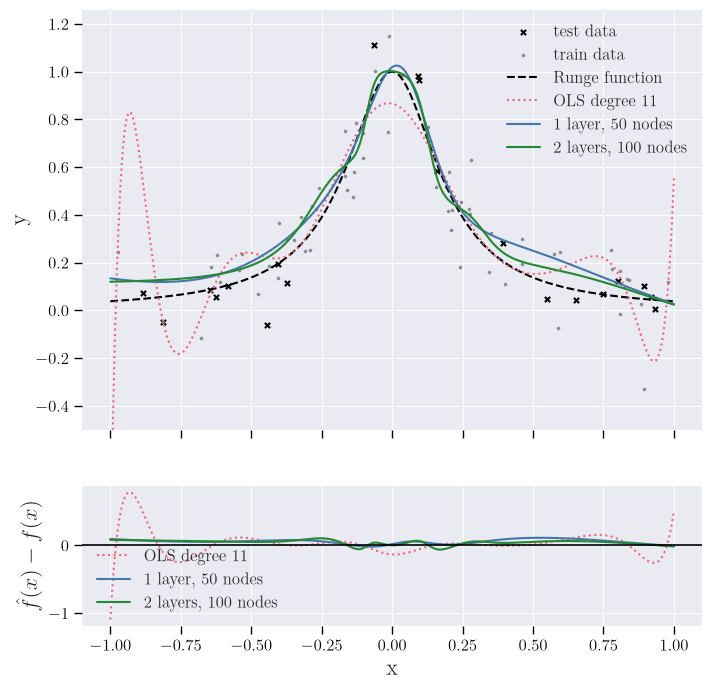

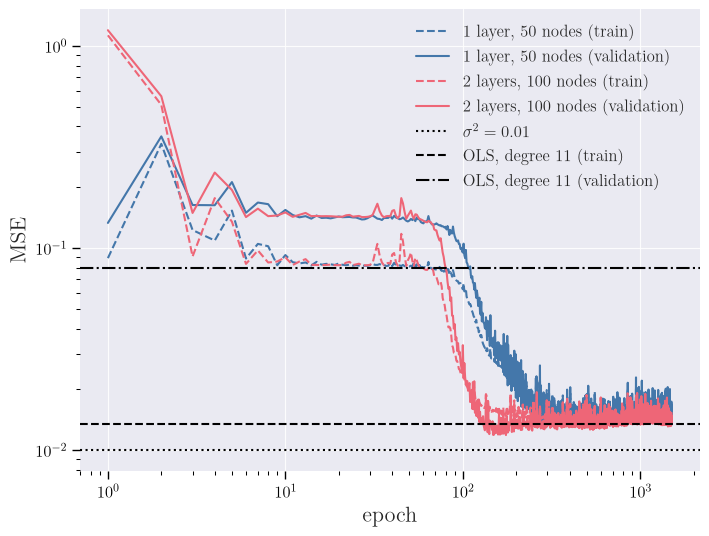

In [6]:
"""Training for plot_NN_vs_OLS"""
models = {}
histories = {}

architectures = {
    "1 layer, 50 nodes": [1, 50, 1],
    "2 layers, 100 nodes": [1, 100, 100, 1]}

for label, layers in architectures.items():

    network = FFNN(layers,hidden_activation="sigmoid",seed=2026)

    hist = network.fit(X_train, y_train,X_val, y_val,epochs=1500,gamma=0.01,batch_size=16,optimizer="Adam")

    models[label] = network
    histories[label] = hist


plot_NN_vs_OLS(models,scaler,X_train_raw,y_train,bestdegree=11,
               x_test=scaler.inverse_transform(X_test),y_test=y_test)
# OLS of degree 11 fitted on the training set, scored on the training and the validation set
ols_train = MSE(y_train, OLS_pred(X_train_raw, y_train, X_train_raw, degree=11))
ols_val   = MSE(y_val,   OLS_pred(X_train_raw, y_train, X_val_raw,   degree=11))
plot_learning_curves(histories, ols_train, ols_val)

In [7]:
"""training for plotting opt comparizon"""

architectures = {"1 layer, 50 nodes": [1, 50, 1],"2 layers, 100 nodes": [1, 100, 100, 1]}
gammas = np.logspace(-4, 0, 7)
results = comparing_Optimizer(architectures,X_train, y_train,X_val, y_val,gammas=gammas,epochs=1000,mse_type='minimum')

# for OLS

y_ols_val = OLS_pred(X_train_raw,y_train,X_val_raw,degree=11)
ols_val_mse = MSE(y_val, y_ols_val)

# GD stability limit gamma = 2 / lambda_max, with the Hessian of the training cost at the trained networks of the
# NN-vs-OLS cell above (same architectures, trained with Adam) (LLM-assisted, Kimi K2.6)
gd_limits = {}
for label in architectures:
    lam_max = hessian_lambda_max(models[label], X_train, y_train)
    gd_limits[label] = 2.0 / lam_max
    print(f"{label}: lambda_max = {lam_max:.4g}, GD limit 2/lambda_max = {gd_limits[label]:.4g}")


FFNN training: 100%|██████████| 1000/1000 [00:01<00:00, 753.02epoch/s]


1 layer, 50 nodes: lambda_max = 8.274, GD limit 2/lambda_max = 0.2417
2 layers, 100 nodes: lambda_max = 7.102, GD limit 2/lambda_max = 0.2816


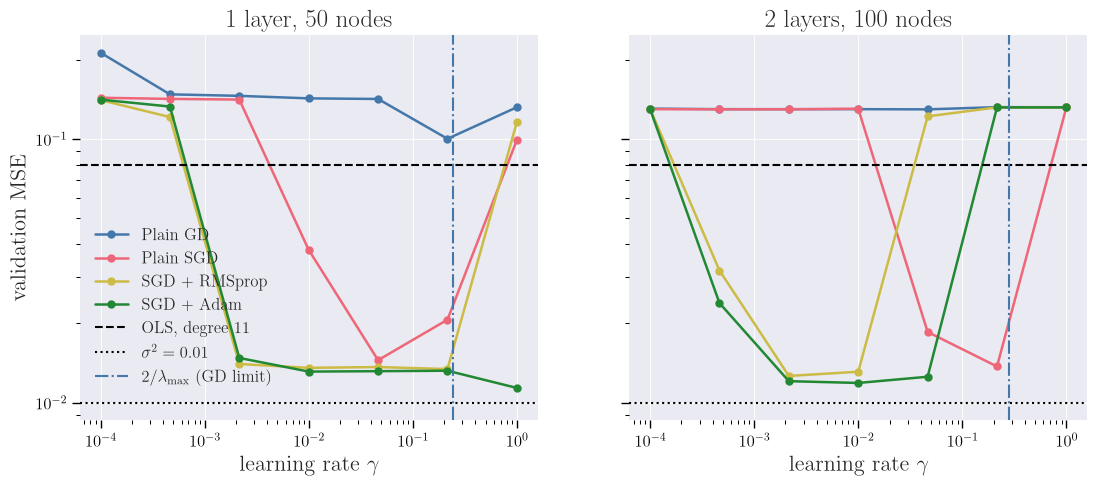

In [8]:
plot_comparing_Optimizers(results,gammas,ols_mse=ols_val_mse,gd_limits=gd_limits)

### Part c): Testing different activation functions and depths of the neural network

You should also test different activation functions for the hidden layers. Try out the Sigmoid, the RELU and the Leaky RELU functions and discuss your results (Section [8.6.4](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#which-activation-should-we-use) of the lecture notes discusses which activation to use, and Section [8.9](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#vanishing-and-exploding-gradients) why the sigmoid makes the gradients vanish in deep networks). Test your results as functions of the number of hidden layers and nodes. Do you see signs of overfitting? It is optional in this project to perform a bias-variance trade-off analysis.


FFNN training: 100%|██████████| 1500/1500 [00:01<00:00, 887.84epoch/s]


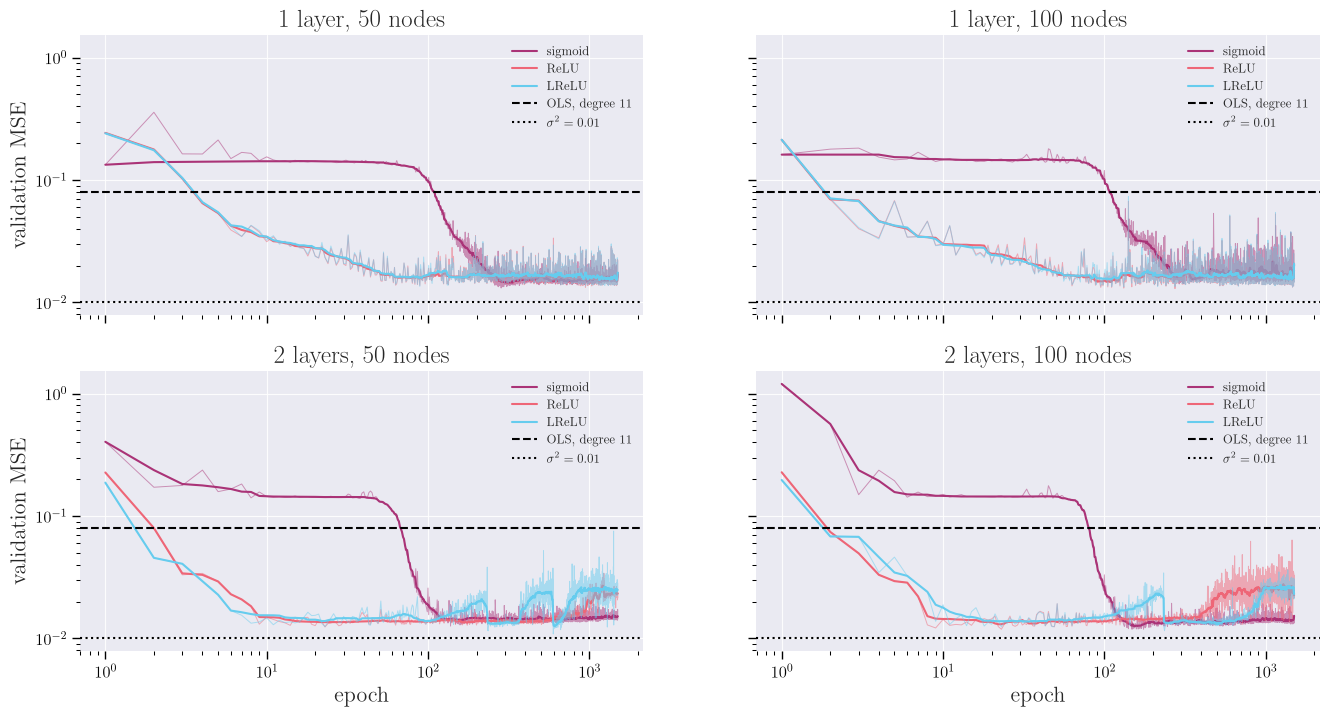

Architecture              Activation   Best epoch    Train MSE      Val MSE  Val R2 (final)
-------------------------------------------------------------------------------
1 layer, 50 nodes         sigmoid             284     0.018983     0.013122        0.868162
1 layer, 50 nodes         ReLU                946     0.014736     0.013301        0.871306
1 layer, 50 nodes         LReLU                89     0.016426     0.013533        0.867151
1 layer, 100 nodes        sigmoid             291     0.017381     0.014154        0.862599
1 layer, 100 nodes        ReLU                274     0.017066     0.012963        0.846295
1 layer, 100 nodes        LReLU              1466     0.014738     0.013358        0.842986
2 layers, 50 nodes        sigmoid             138     0.017628     0.012620        0.884798
2 layers, 50 nodes        ReLU                 23     0.015486     0.012413        0.823458
2 layers, 50 nodes        LReLU               599     0.014157     0.010887        0.811234


In [9]:
"""
Training for comparison of different activation functions
"""

histories_different_activations = {}
networks_different_activations = {}     # the trained networks, for the results table (LLM-assisted, Kimi K2.6)
architectures = {
    "1 layer, 50 nodes": [1, 50, 1],
    "1 layer, 100 nodes": [1,100,1],
    "2 layers, 50 nodes": [1, 50, 50, 1],
    "2 layers, 100 nodes": [1, 100, 100, 1]}

activation_functions =["sigmoid", "ReLU","LReLU"]

for label, layers in architectures.items():

    histories_different_activations[label] = {}
    networks_different_activations[label] = {}

    for hid_act in activation_functions:
        NeuNetw = FFNN(layers,hidden_activation=hid_act,seed=2026)
        hist    = NeuNetw.fit(X_train,y_train,X_val,y_val,epochs=1500,gamma=0.01,batch_size=16,optimizer="Adam")
        histories_different_activations[label][hid_act]= hist
        networks_different_activations[label][hid_act] = NeuNetw

plot_comparing_Activations(histories_different_activations, ols_mse=ols_val_mse)

print(f"{'Architecture':<25} {'Activation':<10} "
  f"{'Best epoch':>12} {'Train MSE':>12} "
  f"{'Val MSE':>12} {'Val R2 (final)':>15}")
print(f"-------------------------------------------------------------------------------")

for architecture, results in histories_different_activations.items():
    for act, hist in results.items():

        train = np.asarray(hist["train_mse"])
        val = np.asarray(hist["val_mse"])
        r2 = r2_score(y_val, networks_different_activations[architecture][act].predict(X_val))   # final network
        idx = np.argmin(val)

        print(
            f"{architecture:<25} {act:<10} "
            f"{idx+1:>12} {train[idx]:>12.6f} "
            f"{val[idx]:>12.6f}"
            f"{r2:>16.6f}"
        )

### Part d): Testing different norms

Finally, still using the one-dimensional Runge function, add now the hyperparameters $\lambda$ with the $L_2$ and $L_1$ norms (Section [8.12](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#regularisation-and-hyperparameters) of the lecture notes). Find the optimal results for the hyperparameters $\lambda$ and the learning rates $\gamma$ and neural network architecture and compare the $L_2$ results with Ridge regression from project 1 and the $L_1$ results with the Lasso calculations of project 1. Use again the same data sets and the best results from project 1 in your comparisons.


Part d) uses our own network functions (`create_layers`, `backpropagation`, `train`), which the classification below also uses, but the same data, split, scaling, minibatch size (16), number of epochs (1500), learning rates and architectures as parts b) and c). The hyperparameters are chosen on the validation set, and the test set is used once for the selected models.

In [10]:
# Part d) uses the data, split and scaling of parts b) and c) (cell above), as 1D arrays
sigma = 0.1
x_train = X_train_raw.ravel()
x_val   = X_val_raw.ravel()
x_test  = scaler.inverse_transform(X_test).ravel()
yd_train, yd_val, yd_test = y_train.ravel(), y_val.ravel(), y_test.ravel()
print(len(x_train), len(x_val), len(x_test))

64 16 20


In [11]:
from sklearn.model_selection import train_test_split


def design_matrix(x, p):
    X = np.zeros((len(x), p))
    for i in range(1, p + 1):
        X[:, i - 1] = x**i
    return X


# exercises/week35.py, cell 2, with pinv instead of inv
def OLS_parameters(X, y):
    return np.linalg.pinv(X.T @ X) @ X.T @ y


def scale_features(x_train, x_test, degree):
    """Design matrices standardised with the training mean and std"""
    X_train = design_matrix(x_train, degree)
    X_test  = design_matrix(x_test, degree)

    X_mean = X_train.mean(axis=0)
    X_std  = X_train.std(axis=0)

    return (X_train - X_mean) / X_std, (X_test - X_mean) / X_std


# fitted on the training set of parts b) and c)
# degree 11, the best OLS degree from the 10-fold cross-validation of project 1
degree_ols = 11
y_mean = yd_train.mean()
Xp_train, Xp_test = scale_features(x_train, x_test, degree_ols)
theta_ols = OLS_parameters(Xp_train, yd_train - y_mean)
y_train_ols = Xp_train @ theta_ols + y_mean
y_test_ols = Xp_test @ theta_ols + y_mean

print(f"OLS degree {degree_ols}: train MSE {mse(yd_train, y_train_ols)}, test MSE {mse(yd_test, y_test_ols)}, "
      f"test R2 {R_squared(yd_test, y_test_ols)}")

OLS degree 11: train MSE 0.013530629198312084, test MSE 0.03593012943778459, test R2 0.7099087196581018


In [12]:
# The input of the network is just x, scaled: no polynomial features are needed
X_train_nn, X_test_nn = scale_features(x_train, x_test, 1)
_, X_val_nn = scale_features(x_train, x_val, 1)
y_train_nn = (yd_train - y_mean).reshape(-1, 1)


def create_layers(network_input_size, layer_output_sizes, seed=2026):
    """W ~ N(0, 1/n_in) (Section 8.10), small constant bias so that no node starts at exactly zero"""
    rng    = np.random.default_rng(seed)
    layers = []
    i_size = network_input_size
    for o_size in layer_output_sizes:
        W = rng.normal(0.0, 1.0 / np.sqrt(i_size), size=(i_size, o_size))
        b = np.full(o_size, 0.01)
        layers.append((W, b))
        i_size = o_size
    return layers

def feed_forward_saver(X, layers, activation_funcs):
    """Feed forward, keeping the input a and the z of every layer for backpropagation"""
    layer_inputs, zs = [], []
    a = X
    for (W, b), activation_func in zip(layers, activation_funcs):
        layer_inputs.append(a)
        z = a @ W + b
        a = activation_func(z)
        zs.append(z)
    return layer_inputs, zs, a

def feed_forward(X, layers, activation_funcs):
    return feed_forward_saver(X, layers, activation_funcs)[2]

def backpropagation(X, y, layers, activation_funcs, activation_ders, lam=0.0, regularization=None, cost="mse"):
    # The four equations, for all samples at once. Returns [(dW, db), ...] with the shapes of [(W, b), ...].
    if regularization not in (None, "ridge", "lasso"):
        raise ValueError(f"unknown regularization {regularization}")
    a, z, predict = feed_forward_saver(X, layers, activation_funcs)   # a[l] = input of layer l, z[l] = its z
    if cost == "cross_entropy":                          # softmax output + cross entropy: the softmax Jacobian cancels
        delta = cross_entropy_der(predict, y)
    else:                                                # identity output + MSE
        delta = mse_der(predict, y)
    grads = [None] * len(layers)
    for l in range(len(layers) - 1, -1, -1):
        W = layers[l][0]
        dW = a[l].T @ delta                              # dC/dW = A^T Delta,  dC/db = sum of rows
        if regularization == "ridge":
            dW = dW + l2_der(W, lam)
        elif regularization == "lasso":
            dW = dW + l1_der(W, lam)
        grads[l] = (dW, np.sum(delta, axis=0))

        if l > 0:
            delta = (delta @ W.T) * activation_ders[l - 1](z[l - 1])   # one layer back
    return grads


# Check of the gradients against automatic differentiation
def max_grad_difference(grads_a, grads_b):
    diffs = []
    for (dW_a, db_a), (dW_b, db_b) in zip(grads_a, grads_b):
        diffs.append(np.max(np.abs(dW_a - np.asarray(dW_b))))
        diffs.append(np.max(np.abs(db_a - np.asarray(db_b))))
    return max(diffs)


def cost_jax(layers, X, y):
    a = X
    for W, b in layers[:-1]:
        a = jax.nn.sigmoid(a @ W + b)
    W, b = layers[-1]
    return jnp.mean((a @ W + b - y)**2)


hidden_check = (50, 100)
layers_check = create_layers(1, list(hidden_check) + [1])
funcs_check = [sigmoid] * len(hidden_check) + [identity]
ders_check  = [sigmoid_der] * len(hidden_check) + [identity_der]

grads_bp = backpropagation(X_train_nn, y_train_nn, layers_check, funcs_check, ders_check)
grads_jax = jax.grad(cost_jax)(layers_check, X_train_nn, y_train_nn)

print("max |backprop - JAX|:", max_grad_difference(grads_bp, grads_jax))

max |backprop - JAX|: 1.1102230246251565e-16


Machine precision

In [13]:
# LLM-assisted (Kimi K2.6, level 2): validation-cost tracking (X_val, Y_val) in train()
# WeeklyMaterial/week38/week38tuesday.ipynb, cell 7
def optimiser_step(method, theta, g, state, t, gamma, beta=0.9, rho=0.99, beta1=0.9, beta2=0.999, eps=1e-8):
    """One update from the gradient g at step t = 1, 2, ...; Eqs. (4.10), (4.28), (4.42)-(4.45), (4.47)-(4.48), (4.51)-(4.55)"""
    if method == "plain":
        return theta - gamma * g, state

    if method == "momentum":
        state["v"] = beta * state.get("v", 0.0) + gamma * g
        return theta - state["v"], state

    if method == "adagrad":
        state["r"] = state.get("r", 0.0) + g * g
        return theta - gamma * g / (np.sqrt(state["r"]) + eps), state

    if method == "rmsprop":
        state["r"] = rho * state.get("r", 0.0) + (1.0 - rho) * g * g
        return theta - gamma * g / (np.sqrt(state["r"]) + eps), state

    if method == "adam":
        state["m"] = beta1 * state.get("m", 0.0) + (1.0 - beta1) * g
        state["r"] = beta2 * state.get("r", 0.0) + (1.0 - beta2) * g * g
        m_hat = state["m"] / (1.0 - beta1**t)
        r_hat = state["r"] / (1.0 - beta2**t)
        return theta - gamma * m_hat / (np.sqrt(r_hat) + eps), state

    raise ValueError(f"unknown method {method}")


def update_layers(layers, grads, states, method, t, gamma):
    """One optimiser step for the W and b of every layer"""
    new_layers = []
    for (W, b), (dW, db), (state_W, state_b) in zip(layers, grads, states):
        W_new = optimiser_step(method, W, dW, state_W, t, gamma)[0]
        b_new = optimiser_step(method, b, db, state_b, t, gamma)[0]
        new_layers.append((W_new, b_new))
    return new_layers


def train_epoch(X, Y, layers, activation_funcs, activation_ders, states, t, method, gamma, M, rng,
                lam, regularization, cost):
    """One pass over the data in shuffled minibatches of size M; t counts the steps (needed by Adam)"""
    order = rng.permutation(len(X))
    for s in range(0, len(X), M):
        t += 1
        idx = order[s:s + M]
        grads = backpropagation(X[idx], Y[idx], layers, activation_funcs, activation_ders, lam, regularization, cost)
        layers = update_layers(layers, grads, states, method, t, gamma)
    return layers, t


def train(X, Y, layers, activation_funcs, activation_ders, method="plain", gamma=0.1, epochs=100,
          batch_size=None, rng=None, lam=0.0, regularization=None, cost="mse", X_val=None, Y_val=None):
    # Gradient descent on minibatches (batch_size=None: all data in every step), one optimiser state per W and b.
    # some rewrting of weekly_material/week42/week42monday.ipynb
    # If X_val, Y_val are given, their cost after every epoch is stored in history["val_cost"].
    if rng is None:
        rng = np.random.default_rng(2026)

    M = batch_size
    if batch_size is None:
        M = len(X)

    cost_func = mse
    if cost == "cross_entropy":
        cost_func = cross_entropy

    # states keeps history of all W and b gradients from optimiser_step
    states = []
    for _ in layers:
        states.append(({}, {}))

    t = 0
    history = {"cost": [], "val_cost": []}
    for epoch in range(epochs):
        layers, t = train_epoch(X, Y, layers, activation_funcs, activation_ders, states, t, method, gamma, M, rng,
                                lam, regularization, cost)
        history["cost"].append(float(cost_func(feed_forward(X, layers, activation_funcs), Y)))
        if X_val is not None:
            history["val_cost"].append(float(cost_func(feed_forward(X_val, layers, activation_funcs), Y_val)))
        if not np.isfinite(history["cost"][-1]):     # diverged
            break
    return layers, history


def predict_network(X, layers, activation_funcs):
    return feed_forward(X, layers, activation_funcs).ravel() + y_mean

In [14]:
# LLM-assisted (Kimi K2.6, level 1): shared setup collected here when merging
activations = {"sigmoid": (sigmoid, sigmoid_der), "ReLU": (ReLU, ReLU_der), "leaky ReLU": (ReLU_leaky, ReLU_leaky_der)}


def regression_run(act, n_layers, n_nodes, method="adam", gamma=1e-2, epochs=1500, lam=0.0, regularization=None):
    f, df = activations[act]
    funcs = [f] * n_layers + [identity]
    ders = [df] * n_layers + [identity_der]
    layers = create_layers(1, [n_nodes] * n_layers + [1])
    layers, _ = train(X_train_nn, y_train_nn, layers, funcs, ders, method, gamma, epochs=epochs, batch_size=16,
                      lam=lam, regularization=regularization)
    train_mse = mse(yd_train, predict_network(X_train_nn, layers, funcs))
    val_mse = mse(yd_val, predict_network(X_val_nn, layers, funcs))
    test_mse = mse(yd_test, predict_network(X_test_nn, layers, funcs))
    return train_mse, val_mse, test_mse, layers, funcs


# fine grid
xx = np.linspace(-1, 1, 400)
_, xx_nn = scale_features(x_train, xx, 1)
_, xx_poly = scale_features(x_train, xx, degree_ols)

In [15]:
# From project 1
from sklearn.linear_model import Lasso


# Project1.ipynb, cell 20: minimises (1/n)||y - X theta||^2 + lam ||theta||^2
def Ridge_parameters(X, y, lam):
    n_rows, p = X.shape
    return np.linalg.solve(X.T @ X + n_rows * lam * np.eye(p), X.T @ y)


# Project1.ipynb, cell 47: sklearn minimises (1/(2n))||y - X theta||^2 + alpha ||theta||_1, so alpha = lambda/2
def lasso_fit(X, y, lam):
    return Lasso(alpha=lam / 2.0, fit_intercept=False, max_iter=100000, tol=1e-8).fit(X, y).coef_


# best models of the 10-fold cross-validation in part i) of project 1 (Project1.ipynb, cell 47)
degree_ridge = 12
lam_ridge = 1e-7
degree_lasso = 11
lam_lasso = 10**-3.5

p1_models = {}      # name: (degree, theta, test MSE)
for name, fit, degree, lam in (("Ridge", Ridge_parameters, degree_ridge, lam_ridge),
                               ("Lasso", lasso_fit, degree_lasso, lam_lasso)):
    X_tr, X_te = scale_features(x_train, x_test, degree)
    theta = fit(X_tr, yd_train - y_mean, lam)
    y_tr_pred = X_tr @ theta + y_mean
    y_te_pred = X_te @ theta + y_mean
    p1_models[name] = (degree, theta, mse(yd_test, y_te_pred))
    print(f"{name} degree {degree}, lambda {lam}: train MSE {mse(yd_train, y_tr_pred)}, "
          f"test MSE {mse(yd_test, y_te_pred)}, test R2 {R_squared(yd_test, y_te_pred)}")

Ridge degree 12, lambda 1e-07: train MSE 0.013365758932686801, test MSE 0.026627439025769174, test R2 0.7850164193650764
Lasso degree 11, lambda 0.00031622776601683794: train MSE 0.01580586432161009, test MSE 0.024734827539071528, test R2 0.8002969123094892


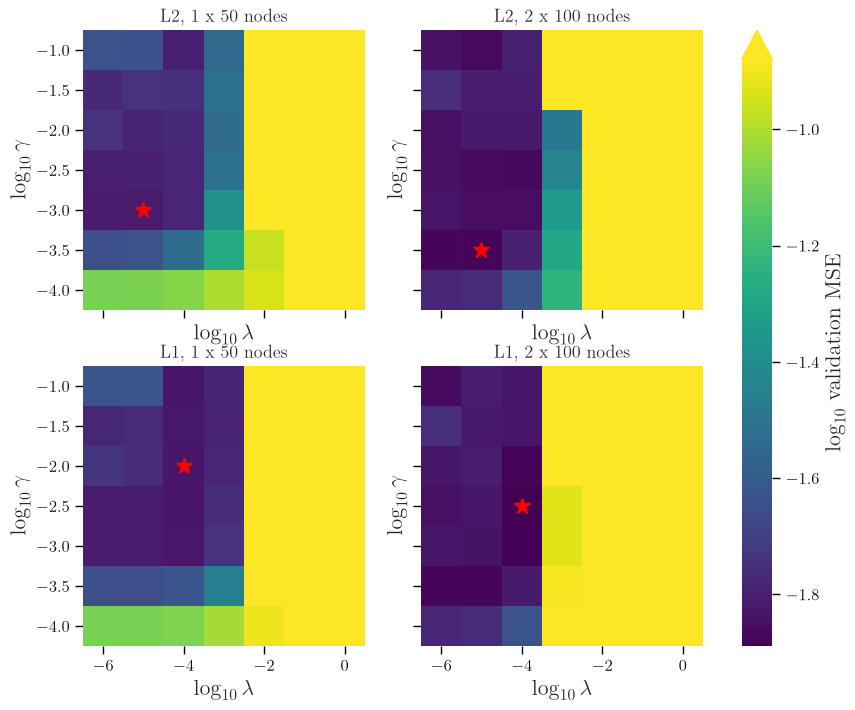

NN L2: 2 x 100 nodes, lambda 1e-05, gamma 3e-04, validation MSE 0.01319, test MSE 0.01371  |  Ridge (project 1), degree 12: test MSE 0.02663
NN L1: 2 x 100 nodes, lambda 1e-04, gamma 3e-03, validation MSE 0.01292, test MSE 0.01572  |  Lasso (project 1), degree 11: test MSE 0.02473


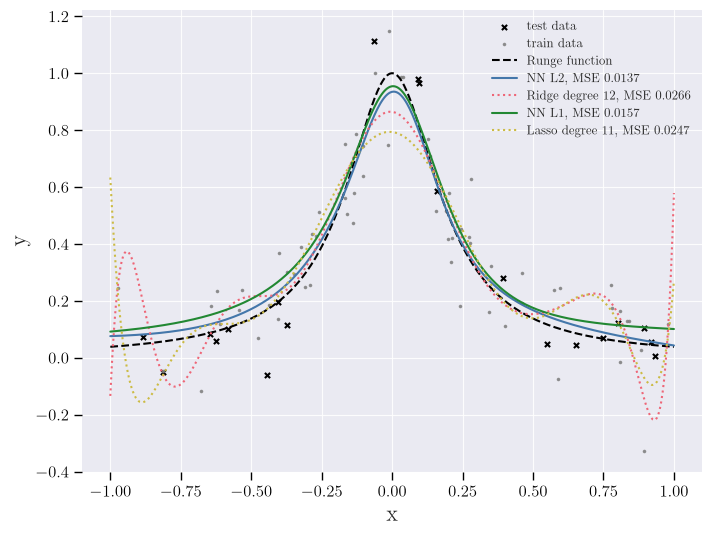

In [16]:
lambdas_d = np.logspace(-6, 0, 7)
gammas_d = np.logspace(-4, -1, 7)       # learning rates and architectures of parts b) and c)
archs_d = ((1, 50), (2, 100))
penalties = ("ridge", "lasso")

settings_d = list(itertools.product(penalties, archs_d, lambdas_d, gammas_d))
tasks = []
for pen, (L, N), lam, gamma in settings_d:
    tasks.append(delayed(regression_run)("sigmoid", L, N, "adam", gamma, 1500, lam, pen))
with np.errstate(over="ignore", invalid="ignore"):
    results_d = dict(zip(settings_d, Parallel(n_jobs=-1)(tasks)))

# validation MSE of every run by (penalty, architecture, gamma, lambda), diverged runs count as infinitely bad,
# and the best run of every penalty, chosen on the validation set
mse_d = {}
best_d = {}
for (pen, arch, lam, gamma), (train_mse, val_mse, test_mse, layers, funcs) in results_d.items():
    mse_d[(pen, arch, gamma, lam)] = val_mse
    score = np.nan_to_num(val_mse, nan=np.inf)
    if pen not in best_d or score < np.nan_to_num(results_d[best_d[pen]][1], nan=np.inf):
        best_d[pen] = (pen, arch, lam, gamma)

vmin, vmax = np.log10(np.nanmin(list(mse_d.values()))), np.log10(np.var(yd_val))
fig, axes = plt.subplots(len(penalties), len(archs_d), figsize=(10, 8), sharex=True, sharey=True)
for (r, pen), (c, (L, N)) in itertools.product(enumerate(penalties), enumerate(archs_d)):
    ax = axes[r, c]
    grid = make_grid(mse_d, (pen, (L, N)), gammas_d, lambdas_d)
    im = ax.pcolormesh(np.log10(lambdas_d), np.log10(gammas_d), np.log10(grid), shading="nearest",
                       cmap="viridis", vmin=vmin, vmax=vmax)
    i, j = np.unravel_index(np.nanargmin(grid), grid.shape)
    ax.plot(np.log10(lambdas_d[j]), np.log10(gammas_d[i]), "r*", ms=12)
    ax.set_title(f"{penalty_name[pen]}, {L} x {N} nodes", fontsize=13)
    ax.set_xlabel(r"$\log_{10}\lambda$")
    ax.set_ylabel(r"$\log_{10}\gamma$")
    ax.grid(False)
fig.colorbar(im, ax=axes, label=r"$\log_{10}$ validation MSE", extend="max")
save_fig(fig, "regression_penalties_heatmap")
plt.show()

# the best network of each penalty against Ridge and Lasso of project 1
fig, ax = plt.subplots()
ax.scatter(x_test, yd_test, s=14, color="k", marker="x", label="test data")
ax.scatter(x_train, yd_train, s=10, color="gray", marker=".", label="train data", alpha=0.8)
ax.plot(xx, runge(xx), "k--", label="Runge function")
for pen, p1_name in (("ridge", "Ridge"), ("lasso", "Lasso")):
    _, (L, N), lam, gamma = best_d[pen]
    _, val_mse, test_mse, layers, funcs = results_d[best_d[pen]]
    degree, theta, p1_mse = p1_models[p1_name]
    print(f"NN {penalty_name[pen]}: {L} x {N} nodes, lambda {lam:.0e}, gamma {gamma:.0e}, validation MSE {val_mse:.5f}, test MSE {test_mse:.5f}"
          f"  |  {p1_name} (project 1), degree {degree}: test MSE {p1_mse:.5f}")
    ax.plot(xx, predict_network(xx_nn, layers, funcs), label=f"NN {penalty_name[pen]}, MSE {test_mse:.4f}")
    _, xx_p = scale_features(x_train, xx, degree)
    ax.plot(xx, xx_p @ theta + y_mean, ":", label=f"{p1_name} degree {degree}, MSE {p1_mse:.4f}")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend(fontsize=9)
save_fig(fig, "regression_penalties_vs_project1")
plt.show()

In [17]:
# LLM-assisted (Kimi K2.6, level 2): regression results table (train MSE, test MSE, test R2) for the report
# Polynomials of project 1 and the networks of parts b), c) and d), all on the same training and test points.
# The networks marked * are chosen on the validation set: per activation the architecture with the lowest final
# validation MSE (part c)), and the best lambda, gamma and architecture per penalty (part d)).
import pandas as pd


def arch_str(hidden):
    return "(" + ",".join(str(h) for h in hidden) + ")"

def pow10(v):
    return f"10^{{{np.log10(v):.3g}}}"

table_rows = []
def add_row(name, y_tr, pred_tr, y_te, pred_te):
    y_tr, pred_tr, y_te, pred_te = (np.ravel(a) for a in (y_tr, pred_tr, y_te, pred_te))
    table_rows.append((name, mse(y_tr, pred_tr), mse(y_te, pred_te), R_squared(y_te, pred_te)))

# polynomial models of project 1, fitted on the training set
add_row(f"OLS, $p={degree_ols}$", yd_train, y_train_ols, yd_test, y_test_ols)
for (name, (degree, theta, _)), lam in zip(p1_models.items(), (lam_ridge, lam_lasso)):
    X_tr_p, X_te_p = scale_features(x_train, x_test, degree)
    add_row(f"{name}, $p={degree}$, $\\lambda={pow10(lam)}$", yd_train, X_tr_p @ theta + y_mean, yd_test, X_te_p @ theta + y_mean)

# networks of part b) (sigmoid, Adam, gamma = 0.01, 1500 epochs, minibatches of 16)
for label, net in models.items():
    add_row(f"NN {arch_str(net.layer_sizes[1:-1])}, sigmoid", y_train, net.predict(X_train), y_test, net.predict(X_test))

# part c): the best architecture of each activation, chosen by the final validation MSE
act_names = {"sigmoid": "sigmoid", "ReLU": "ReLU", "LReLU": "leaky ReLU"}
for act in activation_functions:
    best = min(architectures, key=lambda a: histories_different_activations[a][act]["val_mse"][-1])
    net = networks_different_activations[best][act]
    add_row(f"NN {arch_str(net.layer_sizes[1:-1])}, {act_names[act]}$^*$", y_train, net.predict(X_train), y_test, net.predict(X_test))

# part d): the best network of each penalty, chosen on the validation set
for pen, name in (("ridge", "$L_2$"), ("lasso", "$L_1$")):
    _, (L, N), lam, gamma = best_d[pen]
    _, _, _, layers, funcs = results_d[best_d[pen]]
    add_row(f"NN {arch_str([N] * L)}, {name}, $\\lambda={pow10(lam)}$$^*$",
            yd_train, predict_network(X_train_nn, layers, funcs), yd_test, predict_network(X_test_nn, layers, funcs))

table_regression = pd.DataFrame(table_rows, columns=["model", "train MSE", "test MSE", "test R2"])
print(table_regression.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nnoise variance sigma^2 = {sigma**2}, noise in the test set (MSE of the true function) = "
      f"{mse(yd_test, runge(x_test)):.4f}\n")
for name, tr, te, r2 in table_rows:                      # rows for the LaTeX table
    print(f"{name} & {tr:.4f} & {te:.4f} & {r2:.3f} \\\\")

                                     model  train MSE  test MSE  test R2
                               OLS, $p=11$     0.0135    0.0359   0.7099
          Ridge, $p=12$, $\lambda=10^{-7}$     0.0134    0.0266   0.7850
        Lasso, $p=11$, $\lambda=10^{-3.5}$     0.0158    0.0247   0.8003
                          NN (50), sigmoid     0.0152    0.0157   0.8734
                     NN (100,100), sigmoid     0.0138    0.0122   0.9016
                   NN (50,50), sigmoid$^*$     0.0139    0.0125   0.8993
                         NN (50), ReLU$^*$     0.0142    0.0174   0.8597
                   NN (50), leaky ReLU$^*$     0.0145    0.0178   0.8564
NN (100,100), $L_2$, $\lambda=10^{-5}$$^*$     0.0146    0.0137   0.8893
NN (100,100), $L_1$, $\lambda=10^{-4}$$^*$     0.0158    0.0157   0.8731

noise variance sigma^2 = 0.010000000000000002, noise in the test set (MSE of the true function) = 0.0096

OLS, $p=11$ & 0.0135 & 0.0359 & 0.710 \\
Ridge, $p=12$, $\lambda=10^{-7}$ & 0.0134 & 0.026

In [18]:
# If you only want to run the regression part of the notebook, you can uncomment the following line to stop before the classification part. :)
#raise SystemExit

### Part e): Classification analysis using neural networks

With a well-written code it should now be easy to change the activation function for the output layer.

Here we will change the cost function for our neural network code developed in parts b)–d) in order to perform a classification analysis (Section [8.11](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#classification-with-neural-networks) of the lecture notes). The classification problem we will study is the multiclass MNIST problem of handwritten digits (LeCun, Cortes and Burges), see the description of the data set at <https://www.tensorflow.org/datasets/catalog/mnist>. We will use the softmax cross entropy function discussed in a). In this project you should use the *full* MNIST data set ($70\,000$ images of $28\times 28$ pixels), the one used in the Monday lecture of week 41; the code of that lecture reads exactly the file described below. Note that the Tuesday session of week 41 (and Section [8.14](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#examples) of the lecture notes) uses the much smaller digits data set of Scikit-Learn (`load_digits`, $1797$ images of $8\times 8$ pixels, a different data set of the same kind and not a subset of MNIST). The reduced set is convenient for developing and debugging your code, since every run takes seconds, but the results you report should be for the full MNIST set.

The data set comes with a canonical split into $60\,000$ training images and $10\,000$ test images, each a $28\times 28$ array of grey-scale pixel values between 0 and 255. It can be downloaded, without registering anywhere, as a single NumPy archive (about 11 MB) from <https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz> and loaded with


In [19]:
import urllib.request

if not os.path.exists("mnist.npz"):
    urllib.request.urlretrieve("https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", "mnist.npz")
# Xm/ym (m for MNIST), so that the regression data of parts b)-d) are not overwritten
with np.load("mnist.npz") as data:
    Xm_train, ym_train = data["x_train"], data["y_train"]
    Xm_test, ym_test = data["x_test"], data["y_test"]  # untouched until the end
print(Xm_train.shape, ym_train.shape, Xm_test.shape, ym_test.shape)
# (60000, 28, 28) (60000,) (10000, 28, 28) (10000,)

(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


A feed-forward network takes a vector as input, so flatten each image to a vector of $784$ features and scale the pixel values to the interval $[0,1]$ (scaling makes a real difference for gradient descent, see Section 3.13 of the lecture notes),


In [20]:
Xm_train = Xm_train.reshape(len(Xm_train), -1) / 255.0
Xm_test = Xm_test.reshape(len(Xm_test), -1) / 255.0

Use the canonical split the way it is meant to be used: all training, model selection and tuning of hyperparameters (learning rate, penalty $\lambda$, number of layers and nodes, activation functions) is done on the training data only, for example by setting aside a validation set from the training data or by cross-validation (Chapter 3 of the lecture notes). The test set is used *once*, at the very end, to report the performance of the models you have selected. If you are limited by computing time, you may train on a subset of the training images, but evaluate on the full test set.

Remember to cite the data set in your report, as you would cite any other source; the citation is given on the data set page above (Y. LeCun, C. Cortes and C. J. C. Burges, *The MNIST database of handwritten digits*, <http://yann.lecun.com/exdb/mnist/>).

Feel free to suggest other data sets. If you find the classic MNIST data set somewhat limited, try the Fashion-MNIST data set of Zalando Research at <https://github.com/zalandoresearch/fashion-mnist>. It has exactly the same format and the same $60\,000/10\,000$ split, with ten classes of clothing items instead of digits, and the download links, loading code and the reference to cite are all on that page.

To measure the performance of our classification problem we will use the so-called *accuracy* score (Section 5.12 of the lecture notes). The accuracy is as you would expect just the number of correctly guessed targets $t_i$ divided by the total number of targets, that is

$$
\text{Accuracy} = \frac{\sum_{i=1}^n I(t_i = y_i)}{n} ,
$$

where $I$ is the indicator function, $1$ if $t_i = y_i$ and $0$ otherwise. Here $t_i$ represents the target and $y_i$ the outputs of your FFNN code and $n$ is simply the number of targets $t_i$.

Discuss your results and give a critical analysis of the various parameters, including hyperparameters like the learning rates and the regularization parameter $\lambda$, various activation functions, number of hidden layers and nodes and activation functions.

Again, we strongly recommend that you compare your own neural network code for classification and pertinent results against a similar code using **Scikit-Learn** or **TensorFlow/Keras** or **PyTorch** (see the paragraph on established libraries in Section [8.14](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#examples) of the lecture notes).

You should also compare your neural network results with those from logistic regression (Sections 5.3 and 5.6 of the lecture notes). Logistic regression is the *baseline* for the classification part: it is the classifier with no hidden layers, and a network with one or more hidden layers is only worth its extra cost if you can show that it performs better than this baseline. Your neural network code implements the equivalent of logistic regression by simply setting the number of hidden layers to zero and keeping just the input and the output layers (with the softmax activation and the cross entropy cost from part a)).

In addition to the accuracy, you should compute and interpret the *confusion matrix* of your best classification model (Section 5.12 of the lecture notes, see also <https://www.researchgate.net/figure/Confusion-matrix-of-MNIST-and-F-MNIST-embeddings_fig5_349758607>). The confusion matrix shows which digits are confused with which, something a single accuracy number hides, and if you also report the precision, the recall and the $F_1$ score, the confusion matrix is what makes these numbers interpretable. Scikit-Learn’s `confusion_matrix` and `ConfusionMatrixDisplay` from `sklearn.metrics` are convenient for this.

If you wish to compare with logistic regression from **Scikit-Learn** as well, the following code uses the flattened and scaled arrays from above


In [21]:
# A validation set of 10 000 images is set aside from the training data for all tuning. The grid searches train
# on 10 000 of the remaining images to save time; the final models are trained on all 60 000 training images.
X_tr, Xm_val, y_tr, ym_val = train_test_split(Xm_train, ym_train, test_size=10000, random_state=2026, stratify=ym_train)
X_tr, y_tr = X_tr[:10000], y_tr[:10000]
print(X_tr.shape, Xm_val.shape)


def one_hot(y, n_classes=10):
    out = np.zeros((len(y), n_classes))
    out[np.arange(len(y)), y] = 1.0
    return out

(10000, 784) (10000, 784)


In [22]:
def classifier(hidden, act):
    """Layers, activations and derivatives of a network with a softmax output; hidden=() is logistic regression"""
    f, df = activations[act]
    funcs = [f] * len(hidden) + [softmax]
    ders = [df] * len(hidden) + [identity_der]
    return create_layers(784, list(hidden) + [10]), funcs, ders


def mnist_run(hidden, act, regularization, lam, gamma, X, y, X_eval, y_eval, epochs=20):
    layers, funcs, ders = classifier(hidden, act)
    layers, _ = train(X, one_hot(y), layers, funcs, ders, "adam", gamma, epochs=epochs, batch_size=100,
                      lam=lam, regularization=regularization, cost="cross_entropy")
    result = dict(architecture=hidden, activation=act, regularization=regularization, lam=lam, learning_rate=gamma,
                  train_accuracy=accuracy_score(y, feed_forward(X, layers, funcs).argmax(axis=1)),
                  accuracy=accuracy_score(y_eval, feed_forward(X_eval, layers, funcs).argmax(axis=1)))
    return result, layers, funcs


# Check of the softmax cross-entropy gradients against automatic differentiation
def cost_ce_jax(layers, X, Y):
    a = X
    for W, b in layers[:-1]:
        a = jax.nn.relu(a @ W + b)
    W, b = layers[-1]
    return -jnp.mean(jnp.sum(Y * jax.nn.log_softmax(a @ W + b), axis=1))


layers_ce, funcs_ce, ders_ce = classifier((20,), "ReLU")
grads_bp = backpropagation(X_tr[:50], one_hot(y_tr[:50]), layers_ce, funcs_ce, ders_ce, cost="cross_entropy")
grads_jax = jax.grad(cost_ce_jax)(layers_ce, X_tr[:50], one_hot(y_tr[:50]))
print("max |backprop - JAX|:", max_grad_difference(grads_bp, grads_jax))

max |backprop - JAX|: 2.42861286636753e-17


In [23]:
# Grid 1: learning rate and lambda, for the L2 and L1 penalties, one hidden layer of 100 ReLU nodes
regularizations = ("ridge", "lasso")
learning_rates = np.logspace(-4, -1, 4)
lambdas = np.logspace(-6, -2, 5)

settings = list(itertools.product(regularizations, lambdas, learning_rates))
tasks = []
for reg, lam, gamma in settings:
    tasks.append(delayed(mnist_run)((100,), "ReLU", reg, lam, gamma, X_tr, y_tr, Xm_val, ym_val))
with np.errstate(over="ignore", invalid="ignore"):
    outputs = Parallel(n_jobs=-1)(tasks)

mnist_results = []
for result, layers, funcs in outputs:
    mnist_results.append(result)

  architecture activation regularization    lam  learning_rate  train_accuracy  accuracy
0       (100,)       ReLU          ridge  1e-06           0.01          0.9992    0.9578
1       (100,)       ReLU          lasso  1e-06           0.01          0.9943    0.9543
2       (100,)       ReLU          lasso 0.0001           0.01          0.9871    0.9542
3       (100,)       ReLU          ridge  1e-05           0.01          0.9948    0.9539
4       (100,)       ReLU          lasso  1e-05           0.01          0.9944    0.9517
5       (100,)       ReLU          lasso  1e-05          0.001          0.9946    0.9516
6       (100,)       ReLU          ridge 0.0001          0.001          0.9929    0.9511
7       (100,)       ReLU          lasso 0.0001          0.001          0.9822    0.9508
8       (100,)       ReLU          lasso  1e-06          0.001          0.9952    0.9506
9       (100,)       ReLU          ridge  0.001          0.001          0.9805    0.9506


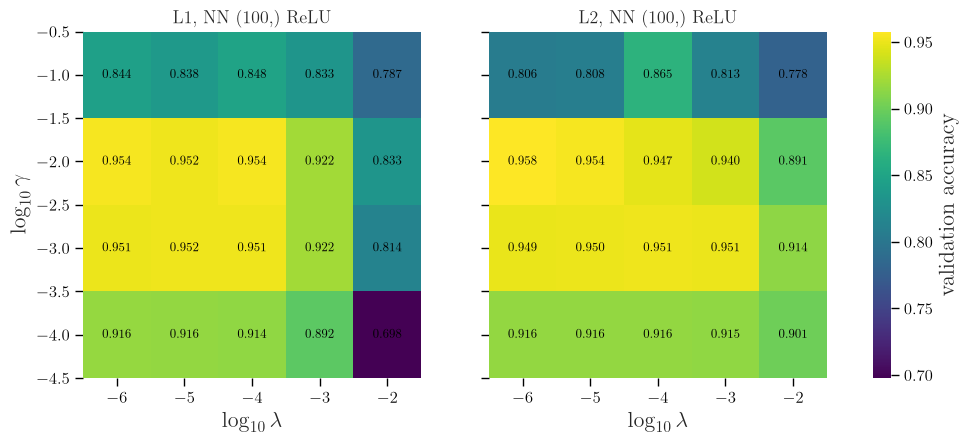

In [24]:
import pandas as pd


def four_digits(v):
    return f"{v:.4g}"


def compare_runs(results, metric="accuracy", top=10):
    df = pd.DataFrame(results).sort_values(metric, ascending=False).reset_index(drop=True)
    print(df.head(top).to_string(float_format=four_digits))

    groups = list(df.groupby("regularization"))
    fig, axes = plt.subplots(1, len(groups), figsize=(6 * len(groups), 4.5), squeeze=False, sharey=True)
    vmin, vmax = df[metric].min(), df[metric].max()
    for ax, (regularization, g) in zip(axes[0], groups):
        grid = g.pivot(index="learning_rate", columns="lam", values=metric)
        x, y = np.log10(grid.columns), np.log10(grid.index)
        im   = ax.pcolormesh(x, y, grid.values, shading="nearest", cmap="viridis", vmin=vmin, vmax=vmax)
        annotate(ax, grid.values, x, y, digits=3)
        ax.set_title(f"{penalty_name[regularization]}, NN (100,) ReLU", fontsize=13)
        ax.set_xlabel(r"$\log_{10}\lambda$")
        ax.grid(False)
    axes[0, 0].set_ylabel(r"$\log_{10}\gamma$")
    fig.colorbar(im, ax=axes, label="validation accuracy")
    save_fig(fig, "mnist_lr_lambda")
    plt.show()
    return df


runs_table = compare_runs(mnist_results)
best_1 = runs_table.iloc[0]

In [25]:
# Grid 2: activation function and architecture, with the best penalty, lambda and learning rate of grid 1
activations_e = list(activations)
architectures_e = ((50,), (100,), (200,), (50, 50), (100, 100), (200, 200))

settings_2 = list(itertools.product(activations_e, architectures_e))
tasks = []
for act, hidden in settings_2:
    tasks.append(delayed(mnist_run)(hidden, act, best_1["regularization"], best_1["lam"], best_1["learning_rate"],
                                    X_tr, y_tr, Xm_val, ym_val))
with np.errstate(over="ignore", invalid="ignore"):
    outputs = Parallel(n_jobs=-1)(tasks)

mnist_results_2 = []
accuracies_2 = {}
for result, layers, funcs in outputs:
    mnist_results_2.append(result)
    accuracies_2[("train_accuracy", result["activation"], result["architecture"])] = result["train_accuracy"]
    accuracies_2[("accuracy", result["activation"], result["architecture"])] = result["accuracy"]

runs_table_2 = pd.DataFrame(mnist_results_2).sort_values("accuracy", ascending=False).reset_index(drop=True)
print(runs_table_2.to_string(float_format=four_digits))
best_2 = runs_table_2.iloc[0]

   architecture  activation regularization   lam  learning_rate  train_accuracy  accuracy
0    (100, 100)     sigmoid          ridge 1e-06           0.01               1    0.9623
1        (200,)     sigmoid          ridge 1e-06           0.01               1    0.9605
2    (100, 100)  leaky ReLU          ridge 1e-06           0.01           0.998     0.959
3    (200, 200)     sigmoid          ridge 1e-06           0.01           0.998    0.9582
4        (100,)        ReLU          ridge 1e-06           0.01          0.9992    0.9578
5        (100,)  leaky ReLU          ridge 1e-06           0.01          0.9985    0.9575
6        (200,)  leaky ReLU          ridge 1e-06           0.01          0.9949    0.9569
7        (100,)     sigmoid          ridge 1e-06           0.01               1    0.9567
8    (100, 100)        ReLU          ridge 1e-06           0.01          0.9959    0.9552
9    (200, 200)  leaky ReLU          ridge 1e-06           0.01          0.9899    0.9539
10       (

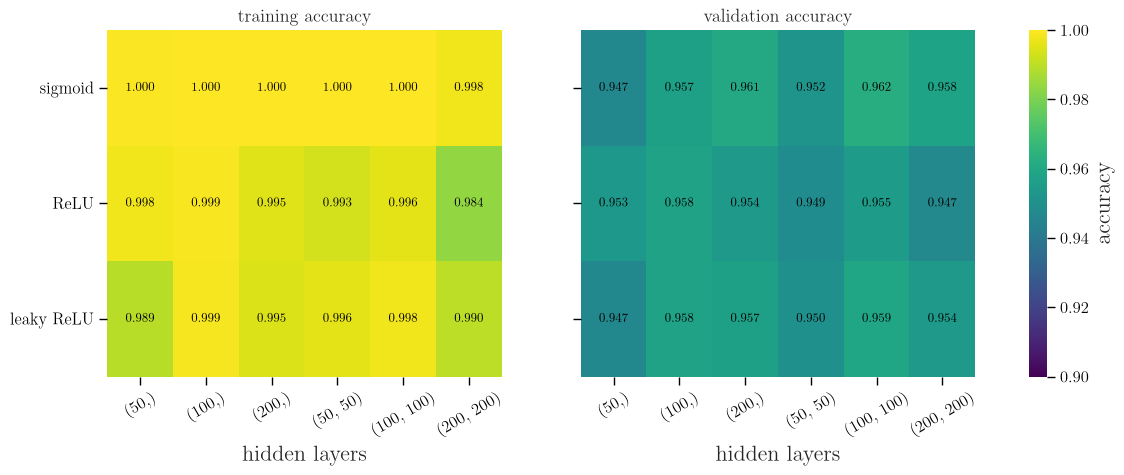

In [26]:
architecture_labels = []
for hidden in architectures_e:
    architecture_labels.append(str(hidden))
titles = {"train_accuracy": "training accuracy", "accuracy": "validation accuracy"}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, metric in zip(axes, ("train_accuracy", "accuracy")):
    grid = make_grid(accuracies_2, (metric,), activations_e, architectures_e)
    im = ax.imshow(grid, cmap="viridis", vmin=0.9, vmax=1.0, aspect="auto")
    annotate(ax, grid, range(len(architectures_e)), range(len(activations_e)), digits=3)
    ax.set_xticks(range(len(architectures_e)), architecture_labels, rotation=30)
    ax.set_title(titles[metric], fontsize=13)
    ax.set_xlabel("hidden layers")
    ax.grid(False)
axes[0].set_yticks(range(len(activations_e)), activations_e)
fig.colorbar(im, ax=axes, label="accuracy")
save_fig(fig, "mnist_activation_architecture")
plt.show()

In [27]:
# Baseline: logistic regression, i.e. our network with zero hidden layers (softmax output + cross entropy)
tasks = []
for gamma in learning_rates:
    tasks.append(delayed(mnist_run)((), "ReLU", None, 0.0, gamma, X_tr, y_tr, Xm_val, ym_val))
with np.errstate(over="ignore", invalid="ignore"):
    outputs = Parallel(n_jobs=-1)(tasks)

best_logreg = None
for result, layers, funcs in outputs:
    print(f"logistic regression, gamma {result['learning_rate']:.0e}: validation accuracy {result['accuracy']:.4f}")
    if best_logreg is None or result["accuracy"] > best_logreg["accuracy"]:
        best_logreg = result

# The same comparisons with Scikit-Learn, on the same training and validation data
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

sk_logreg = LogisticRegression(max_iter=1000, random_state=2026).fit(X_tr, y_tr)
print(f"\nScikit-Learn logistic regression: validation accuracy {sk_logreg.score(Xm_val, ym_val):.4f}")

# sklearn adds alpha/(2 M) ||W||^2 per batch of size M, our L2 term is lam ||W||^2, so alpha = 2 M lam (L2 only)
alpha = 0.0
if best_2["regularization"] == "ridge":
    alpha = 2 * 100 * best_2["lam"]
sklearn_activation = {"sigmoid": "logistic", "ReLU": "relu", "leaky ReLU": "relu"}   # sklearn has no leaky ReLU
sk_mlp = MLPClassifier(hidden_layer_sizes=best_2["architecture"], activation=sklearn_activation[best_2["activation"]],
                       alpha=alpha, batch_size=100, learning_rate_init=best_2["learning_rate"], max_iter=20,
                       random_state=2026).fit(X_tr, y_tr)
print(f"Scikit-Learn MLPClassifier {best_2['architecture']}: validation accuracy {sk_mlp.score(Xm_val, ym_val):.4f}"
      f"  (our network: {best_2['accuracy']:.4f})")

logistic regression, gamma 1e-04: validation accuracy 0.8707
logistic regression, gamma 1e-03: validation accuracy 0.9145
logistic regression, gamma 1e-02: validation accuracy 0.9092
logistic regression, gamma 1e-01: validation accuracy 0.8866

Scikit-Learn logistic regression: validation accuracy 0.9035
Scikit-Learn MLPClassifier (100, 100): validation accuracy 0.9599  (our network: 0.9623)


/home/simon/Desktop/School/semester9/FYS-STK4155/projects/FYSSTK4155-project2/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


In [28]:
# Final evaluation: the selected models are retrained on all 60 000 training images, and the test set is used once
with np.errstate(over="ignore", invalid="ignore"):
    final_nn, layers_nn, funcs_nn = mnist_run(best_2["architecture"], best_2["activation"], best_2["regularization"],
                                              best_2["lam"], best_2["learning_rate"], Xm_train, ym_train, Xm_test, ym_test)
    final_logreg, layers_lr, funcs_lr = mnist_run((), "ReLU", None, 0.0, best_logreg["learning_rate"],
                                                  Xm_train, ym_train, Xm_test, ym_test)
sk_logreg_full = LogisticRegression(max_iter=1000, random_state=2026).fit(Xm_train, ym_train)

test_accuracies = {
    f"our NN {best_2['architecture']} {best_2['activation']}": final_nn["accuracy"],
    "our logistic regression": final_logreg["accuracy"],
    "Scikit-Learn logistic regression": sk_logreg_full.score(Xm_test, ym_test),
}
for name, acc in test_accuracies.items():
    print(f"{name}: test accuracy {acc:.4f}")

our NN (100, 100) sigmoid: test accuracy 0.9770
our logistic regression: test accuracy 0.9282
Scikit-Learn logistic regression: test accuracy 0.9262


In [29]:
# LLM-assisted (Kimi K2.6, level 2): test accuracy of Scikit-Learn's MLPClassifier, retrained like our network
# Same architecture, activation, L2 penalty, minibatch size, learning rate and number of epochs as our selected network,
# trained on all 60 000 training images and evaluated once on the test set
sk_mlp_full = MLPClassifier(hidden_layer_sizes=best_2["architecture"], activation=sklearn_activation[best_2["activation"]],
                            alpha=alpha, batch_size=100, learning_rate_init=best_2["learning_rate"], max_iter=20,
                            random_state=2026).fit(Xm_train, ym_train)
test_accuracies[f"Scikit-Learn MLPClassifier {best_2['architecture']}"] = sk_mlp_full.score(Xm_test, ym_test)
print(f"Scikit-Learn MLPClassifier {best_2['architecture']}: test accuracy {sk_mlp_full.score(Xm_test, ym_test):.4f}"
      f"  (our network: {final_nn['accuracy']:.4f})")

Scikit-Learn MLPClassifier (100, 100): test accuracy 0.9715  (our network: 0.9770)


/home/simon/Desktop/School/semester9/FYS-STK4155/projects/FYSSTK4155-project2/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


              precision    recall  f1-score   support

           0     0.9837    0.9867    0.9852       980
           1     0.9920    0.9894    0.9907      1135
           2     0.9731    0.9806    0.9768      1032
           3     0.9725    0.9802    0.9763      1010
           4     0.9804    0.9684    0.9744       982
           5     0.9689    0.9765    0.9726       892
           6     0.9722    0.9843    0.9782       958
           7     0.9700    0.9737    0.9718      1028
           8     0.9813    0.9702    0.9757       974
           9     0.9738    0.9584    0.9660      1009

    accuracy                         0.9770     10000
   macro avg     0.9768    0.9769    0.9768     10000
weighted avg     0.9770    0.9770    0.9770     10000



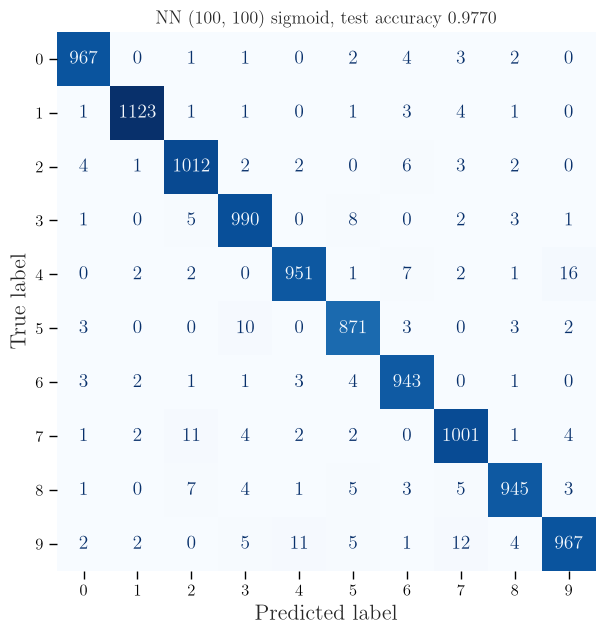

4 classified as 9: 16 times
9 classified as 7: 12 times
7 classified as 2: 11 times
9 classified as 4: 11 times
5 classified as 3: 10 times


In [30]:
# Confusion matrix, precision, recall and F1 of the best model on the test set
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

P = feed_forward(Xm_test, layers_nn, funcs_nn)
pred = P.argmax(axis=1)
print(classification_report(ym_test, pred, digits=4))

cm = confusion_matrix(ym_test, pred)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm).plot(ax=ax, cmap="Blues", colorbar=False)
ax.grid(False)
ax.set_title(f"NN {best_2['architecture']} {best_2['activation']}, test accuracy {final_nn['accuracy']:.4f}", fontsize=13)
save_fig(fig, "mnist_confusion_matrix")
plt.show()

off = cm - np.diag(np.diag(cm))
for k in np.argsort(-off, axis=None)[:5]:
    i, j = np.unravel_index(k, cm.shape)
    print(f"{i} classified as {j}: {cm[i, j]} times")

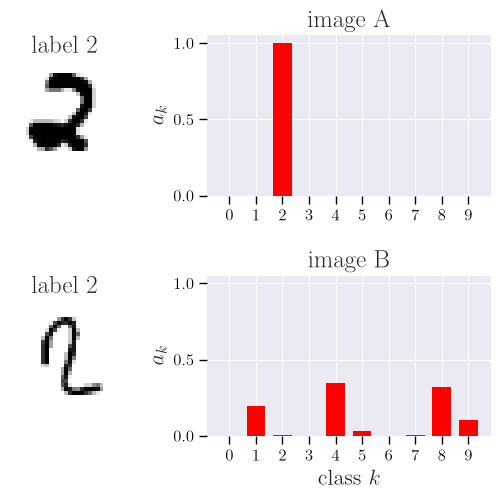

image B: label 2,  one-hot y = [0 0 1 0 0 0 0 0 0 0]
delta_2 = a_2 - y_2 = 0.00 - 1 = -1.00
delta_4 = a_4 - y_4 = 0.35 - 0 = +0.35
delta_8 = a_8 - y_8 = 0.32 - 0 = +0.32
delta_1 = a_1 - y_1 = 0.19 - 0 = +0.19


In [31]:
# The most confident correct prediction (A) and the least confident prediction (B), with the output a = softmax(z)
pmax = P.max(axis=1)
i_A = int(np.argmax(np.where(pred == ym_test, pmax, -1)))
i_B = int(np.argmin(pmax))

fig = plt.figure(figsize=(6.2, 5.2))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2.6], wspace=0.45, hspace=0.5)
for row, (i, name) in enumerate(((i_A, "A"), (i_B, "B"))):
    axi = fig.add_subplot(gs[row, 0])
    axi.imshow(Xm_test[i].reshape(28, 28), cmap="gray_r")
    axi.set_title(f"label {ym_test[i]}")
    axi.set_xticks([])
    axi.set_yticks([])
    axb = fig.add_subplot(gs[row, 1])
    axb.bar(np.arange(10), P[i], color="r", width=0.7)
    axb.set_xticks(np.arange(10))
    axb.set_ylim(0, 1.05)
    axb.set_ylabel("$a_k$")
    axb.set_title(f"image {name}")
axb.set_xlabel("class $k$")
save_fig(fig, "mnist_confident_vs_unsure")
plt.show()

y_B = one_hot(ym_test[i_B:i_B + 1])[0]
delta_B = P[i_B] - y_B
print(f"image B: label {ym_test[i_B]},  one-hot y = {y_B.astype(int)}")
for k in np.argsort(-np.abs(delta_B))[:4]:                       # largest |delta_k| first
    print(f"delta_{k} = a_{k} - y_{k} = {P[i_B, k]:.2f} - {y_B[k]:.0f} = {delta_B[k]:+.2f}")

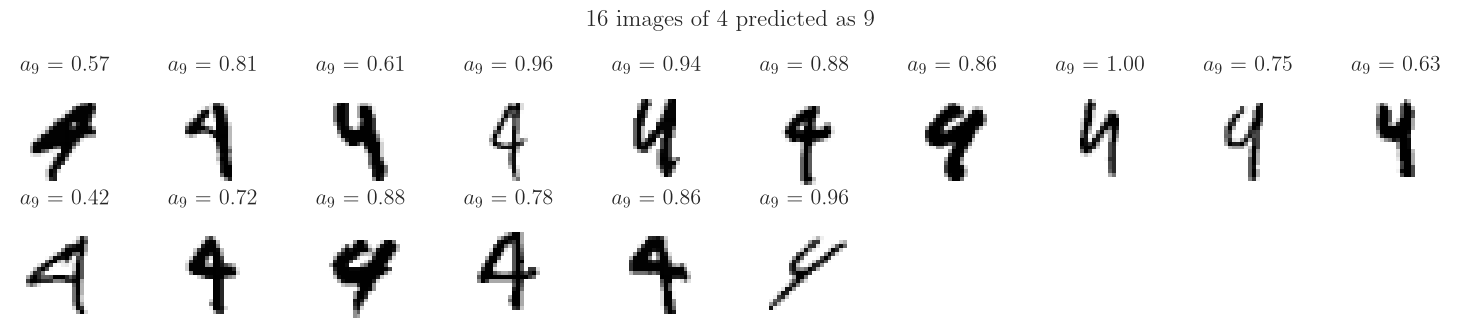

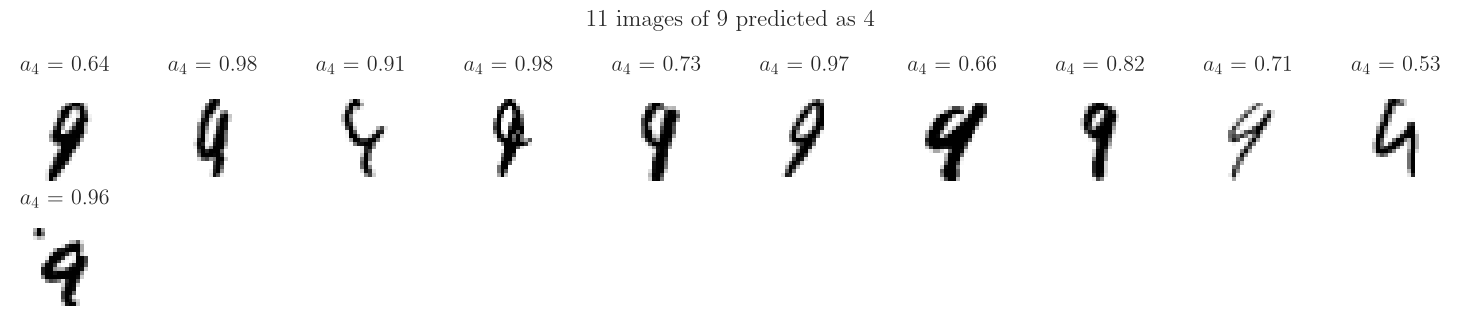

In [32]:
# LLM-assisted (Kimi K2.6, level 2): plotting snippet, and debugging of the figure saving
# All test images where a 4 was predicted as 9, and a 9 as 4, with the network's confidence a_k
for true, wrong in ((4, 9), (9, 4)):
    idx = np.where((ym_test == true) & (pred == wrong))[0]
    n_cols = 10
    n_rows = int(np.ceil(len(idx) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(1.5 * n_cols, 1.7 * n_rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), idx):
        ax.imshow(Xm_test[i].reshape(28, 28), cmap="gray_r")
        ax.set_title(f"$a_{{{wrong}}}$ = {P[i, wrong]:.2f}", fontsize=16)
    fig.suptitle(f"{len(idx)} images of {true} predicted as {wrong}")
    plt.tight_layout()
    save_fig(fig, f"mnist_{true}_as_{wrong}")
    plt.show()

### Part f): Critical evaluation of the various algorithms

After all these glorious calculations, you should now summarize the various algorithms and come with a critical evaluation of their pros and cons. Which algorithm works best for the regression case and which is best for the classification case? Section [8.15](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#limitations-and-a-top-down-view) of the lecture notes gives a top-down view of what neural networks can and cannot do that you may find useful here. These codes can also be part of your final project 3, but now applied to other data sets.


In [33]:
# LLM-assisted (Kimi K2.6, level 1): adapted to the merged notebook
# Part f): all results in one place
rows = [(f"OLS, degree {degree_ols}", mse(yd_test, y_test_ols))]
for name, (degree, theta, p1_mse) in p1_models.items():
    rows.append((f"{name}, degree {degree}", p1_mse))
for pen, (L, N), lam, gamma in best_d.values():
    rows.append((f"NN {penalty_name[pen]} {L}x{N}", results_d[(pen, (L, N), lam, gamma)][2]))



summary_regression = pd.DataFrame(rows, columns=["model", "test MSE"])
print(summary_regression.to_string(index=False, float_format=lambda v: f"{v}"))
print(f"(noise variance sigma^2 = {sigma**2})\n")

summary_classification = pd.DataFrame(list(test_accuracies.items()), columns=["model", "test accuracy"])
print(summary_classification.to_string(index=False, float_format=lambda v : f"{v:.4f}"))

           model             test MSE
  OLS, degree 11  0.03593012943778459
Ridge, degree 12 0.026627439025769174
Lasso, degree 11 0.024734827539071528
     NN L2 2x100 0.013708446900480556
     NN L1 2x100  0.01571791758202285
(noise variance sigma^2 = 0.010000000000000002)

                                model  test accuracy
            our NN (100, 100) sigmoid         0.9770
              our logistic regression         0.9282
     Scikit-Learn logistic regression         0.9262
Scikit-Learn MLPClassifier (100, 100)         0.9715


## Use of AI/LLM tools in the code

**Tools used**
- Kimi K2.6 (https://gpt.uio.no/chat, with api key in vscode, October-November 2026):
Used in parts b, c, d and f
- GPT-5.1 Thinking (https://gpt.uio.no/chat, chat version, October-November 2026): regression code (parts b and c)


**Code contributions**

| Code | LLM level | Description |
|---|---|---|
| `FFNN` class (parts b, c) | 3 | Kimi K2.6 generated the class skeleton (ONLY the skeleton), logic reworked and adapted to the project by us |
| `optimiser_step` in `FYSSTK4155p2.py` | 1 | Kimi K2.6 helped fix a bug |
| Regression plotting functions (parts b, c) | 2 | Kimi K2.6 reworked our plotting skeleton; tweaked by us |
| Understanding and some verification of the regression model | 0-1 | GPT-5.1 Thinking and helped verify the model's performance |
| `train()` validation tracking | 2 | Kimi K2.6 added per-epoch validation cost; tested by us |
| Merging the regression script into the notebook | 1 | Kimi K2.6 helped portingg our 2 different code structures into the code into one notebook and resolved name clashes |
| Plot of misclassified 4s and 9s | 2 | Kimi K2.6 wrote parts of the plotting snippet aswell as a bug fix |
| Part f summary table | 1 | Kimi K2.6 adapted it to the merged notebook |
| The rest | 0 | Written by us |

All LLM-assisted code was tested by us and verified.